Conclusion du Notebook 10
L’évaluation adversariale met en évidence des profils de vulnérabilité différents selon les modèles et les mécanismes d’attaque. ZOO affecte fortement le SVM linéaire et la Régression logistique, alors qu’aucun succès n’a été observé sur XGBoost, Random Forest et LightGBM dans cette configuration. L’attaque HSJ, évaluée sous un scénario local avec \(L_\infty \leq 0.05\), révèle cependant des vulnérabilités pour l’ensemble des modèles, notamment XGBoost, LightGBM et Random Forest. Ces résultats montrent qu’une absence de succès avec une attaque donnée ne permet pas de conclure à une robustesse générale. Le Notebook 11 étudiera donc l’utilisation de l’entraînement contradictoire afin de réduire les vulnérabilités observées.

In [96]:
# ============================================================
# ÉTAPE 31 — EXPORT FINAL NOTEBOOK 10
# ============================================================

import json


EXPORT_DIR = (
    FINAL_DIR
    /
    "exports_for_notebook11"
)

EXPORT_DIR.mkdir(
    exist_ok=True
)


# ------------------------------------------------------------
# Tableaux
# ------------------------------------------------------------

clean_vs_attacks_df.to_csv(
    EXPORT_DIR
    /
    "clean_vs_attacks_metrics.csv",
    index=False
)


asr_df.to_csv(
    EXPORT_DIR
    /
    "asr_summary.csv",
    index=False
)


perturbation_df.to_csv(
    EXPORT_DIR
    /
    "perturbation_summary.csv",
    index=False
)


cost_df.to_csv(
    EXPORT_DIR
    /
    "computational_cost.csv",
    index=False
)


robustness_summary.to_csv(
    EXPORT_DIR
    /
    "robustness_summary.csv",
    index=False
)


np.save(
    EXPORT_DIR
    /
    "common_test_fraud_positions.npy",

    np.asarray(
        common_test_fraud_positions,
        dtype=int
    )
)


manifest = {

    "notebook":
        10,

    "models":
        list(
            REFERENCE_MODEL_ORDER
        ),

    "attacks":
        [
            "ZOO",
            "HopSkipJump"
        ],

    "test_common_frauds":
        int(
            len(
                common_test_fraud_positions
            )
        ),

    "hsj_local_linf_threshold":
        float(
            HSJ_LOCAL_EPS
        ),

    "hsj_mutable_features":
        HSJ_MUTABLE_FEATURES,

    "hsj_immutable_features":
        HSJ_IMMUTABLE_FEATURES,

    "important_note":
        (
            "Les transactions adversariales du Test "
            "sont réservées exclusivement à l'évaluation. "
            "Elles ne doivent jamais être utilisées "
            "pour l'adversarial training du Notebook 11."
        )
}


with open(
    EXPORT_DIR
    /
    "manifest.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=4,
        ensure_ascii=False
    )


print("=" * 70)
print("✅ NOTEBOOK 10 TERMINÉ")
print("=" * 70)

print(
    "Dossier final :",
    FINAL_DIR
)

print(
    "Exports Notebook 11 :",
    EXPORT_DIR
)

✅ NOTEBOOK 10 TERMINÉ
Dossier final : notebook10_final
Exports Notebook 11 : notebook10_final\exports_for_notebook11


In [95]:
# ============================================================
# ÉTAPE 30 — SYNTHÈSE FINALE DE ROBUSTESSE
# ============================================================

asr_wide = (
    asr_df
    .pivot(
        index="Model",
        columns="Attack",
        values="ASR"
    )
    .reset_index()
)


recall_wide = (
    clean_vs_attacks_df
    .pivot(
        index="Model",
        columns="Condition",
        values="Recall"
    )
    .reset_index()
)


recall_wide = (
    recall_wide.rename(
        columns={
            "Clean":
                "Recall_Clean",

            "ZOO":
                "Recall_ZOO",

            "HSJ":
                "Recall_HSJ"
        }
    )
)


robustness_summary = (
    asr_wide
    .merge(
        recall_wide,
        on="Model",
        how="left"
    )
)


robustness_summary = (
    robustness_summary.rename(
        columns={
            "ZOO":
                "ASR_ZOO",

            "HSJ":
                "ASR_HSJ"
        }
    )
)


robustness_summary[
    "Worst_Case_ASR"
] = (
    robustness_summary[
        [
            "ASR_ZOO",
            "ASR_HSJ"
        ]
    ]
    .max(
        axis=1
    )
)


robustness_summary[
    "Worst_Case_Recall"
] = (
    robustness_summary[
        [
            "Recall_ZOO",
            "Recall_HSJ"
        ]
    ]
    .min(
        axis=1
    )
)


robustness_summary = (
    robustness_summary
    .sort_values(
        "Worst_Case_ASR",
        ascending=True
    )
    .reset_index(drop=True)
)


robustness_summary.to_csv(
    FINAL_DIR
    /
    "final_robustness_summary.csv",
    index=False
)


display(
    robustness_summary.round(4)
)

,Model,ASR_HSJ,ASR_ZOO,Recall_Clean,Recall_HSJ,Recall_ZOO,Worst_Case_ASR,Worst_Case_Recall
0,Random Forest,30.1887,0.0000,0.7746,0.5493,0.7746,30.1887,0.5493
1,LightGBM,33.9623,0.0000,0.7606,0.5070,0.7606,33.9623,0.5070
2,XGBoost,35.8491,0.0000,0.7746,0.5070,0.7746,35.8491,0.5070
3,Régression logistique,22.6415,62.2642,0.8310,0.6620,0.3662,62.2642,0.3662
4,SVM linéaire,28.3019,81.1321,0.8028,0.5915,0.1972,81.1321,0.1972


In [94]:
# ============================================================
# ÉTAPE 29 — COÛT COMPUTATIONNEL
# ============================================================

cost_df = (
    all_attack_results
    .groupby(
        [
            "Attack",
            "Model"
        ]
    )
    .agg(

        Mean_Queries=(
            "Query_Count",
            "mean"
        ),

        Median_Queries=(
            "Query_Count",
            "median"
        ),

        Mean_Time_s=(
            "Time_s",
            "mean"
        ),

        Median_Time_s=(
            "Time_s",
            "median"
        ),

        Total_Time_s=(
            "Time_s",
            "sum"
        )
    )
    .reset_index()
)


cost_df[
    "Total_Time_min"
] = (
    cost_df[
        "Total_Time_s"
    ]
    /
    60
)


cost_df.to_csv(
    FINAL_DIR
    /
    "attack_computational_cost.csv",
    index=False
)


display(
    cost_df.round(2)
)

,Attack,Model,Mean_Queries,Median_Queries,Mean_Time_s,Median_Time_s,Total_Time_s,Total_Time_min
0,HSJ,LightGBM,24848.75,24845.0,1.24,1.21,65.78,1.10
1,HSJ,Random Forest,24841.23,24836.0,31.11,30.91,1648.64,27.48
2,HSJ,Régression logistique,24792.00,24792.0,0.81,0.79,43.13,0.72
3,HSJ,SVM linéaire,24792.00,24792.0,0.83,0.81,43.74,0.73
4,HSJ,XGBoost,24852.79,24846.0,2.48,2.39,131.68,2.19
5,ZOO,LightGBM,11867.23,11591.0,26.87,11.30,1424.09,23.73
6,ZOO,Random Forest,12327.60,11591.0,485.66,321.80,25739.95,429.00
7,ZOO,Régression logistique,15573.26,12811.0,12.38,9.17,656.30,10.94
8,ZOO,SVM linéaire,14054.02,12811.0,10.56,9.06,559.53,9.33
9,ZOO,XGBoost,12143.45,11591.0,25.63,23.88,1358.44,22.64


In [93]:
# ============================================================
# ÉTAPE 28 — DÉGRADATION DES MÉTRIQUES
# ============================================================

METRICS = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]


degradation_rows = []


for model_name in REFERENCE_MODEL_ORDER:

    model_rows = (
        clean_vs_attacks_df[
            clean_vs_attacks_df[
                "Model"
            ]
            ==
            model_name
        ]
    )


    clean_row = (
        model_rows[
            model_rows[
                "Condition"
            ]
            ==
            "Clean"
        ]
        .iloc[0]
    )


    for attack_name in [
        "ZOO",
        "HSJ"
    ]:

        attack_row = (
            model_rows[
                model_rows[
                    "Condition"
                ]
                ==
                attack_name
            ]
            .iloc[0]
        )


        row = {
            "Model":
                model_name,

            "Attack":
                attack_name
        }


        for metric in METRICS:

            row[
                f"Delta_{metric}"
            ] = (
                attack_row[
                    metric
                ]
                -
                clean_row[
                    metric
                ]
            )


        degradation_rows.append(
            row
        )


degradation_df = pd.DataFrame(
    degradation_rows
)


degradation_df.to_csv(
    FINAL_DIR
    /
    "metric_degradation.csv",
    index=False
)


display(
    degradation_df.round(4)
)

,Model,Attack,Delta_Accuracy,Delta_Precision,Delta_Recall,Delta_F1,Delta_ROC_AUC
0,XGBoost,ZOO,0.0000,0.0000,0.0000,0.0000,0.0000
1,XGBoost,HSJ,-0.0004,-0.0709,-0.2676,-0.1921,-0.0002
2,Random Forest,ZOO,0.0000,0.0000,0.0000,0.0000,0.0000
3,Random Forest,HSJ,-0.0004,-0.0350,-0.2254,-0.1609,-0.0000
4,LightGBM,ZOO,0.0000,0.0000,0.0000,0.0000,0.0000
5,LightGBM,HSJ,-0.0004,-0.0528,-0.2535,-0.1859,-0.0000
6,SVM linéaire,ZOO,-0.0010,-0.3339,-0.6056,-0.4661,-0.0006
7,SVM linéaire,HSJ,-0.0004,-0.0741,-0.2113,-0.1318,-0.0004
8,Régression logistique,ZOO,-0.0008,-0.1894,-0.4648,-0.2830,-0.0008
9,Régression logistique,HSJ,-0.0003,-0.0561,-0.1690,-0.0912,-0.0005


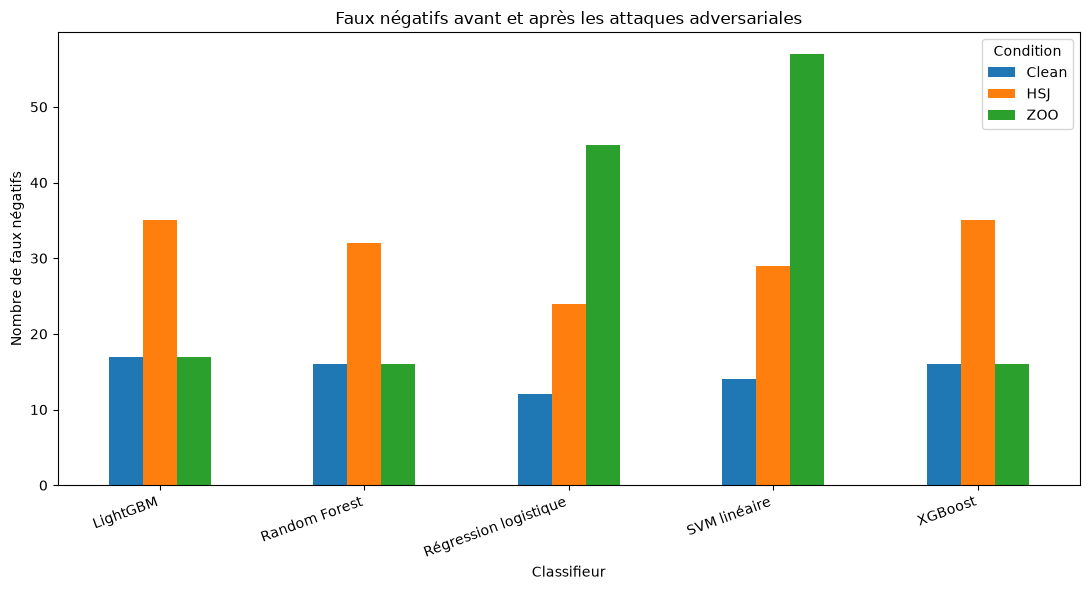

In [92]:
# ============================================================
# ÉTAPE 27 — FAUX NÉGATIFS
# ============================================================

fn_plot = (
    clean_vs_attacks_df
    .pivot(
        index="Model",
        columns="Condition",
        values="FN"
    )
)


ax = fn_plot.plot(
    kind="bar",
    figsize=(11, 6)
)


ax.set_title(
    "Faux négatifs avant et après les attaques adversariales"
)

ax.set_xlabel(
    "Classifieur"
)

ax.set_ylabel(
    "Nombre de faux négatifs"
)


plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()


plt.savefig(
    FINAL_DIR
    /
    "figure_false_negatives.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

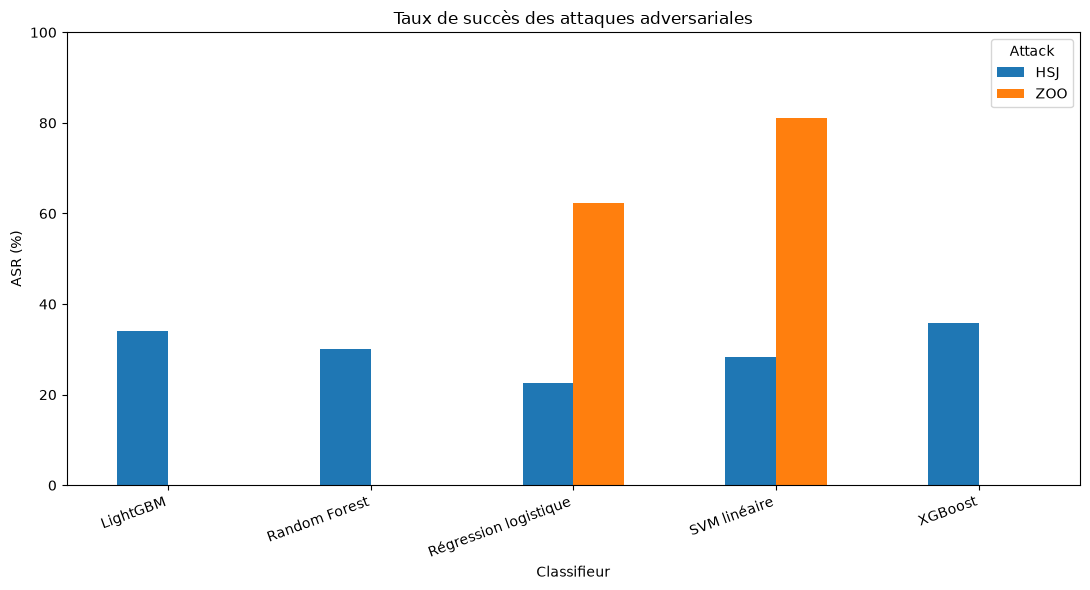

In [91]:
# ============================================================
# ÉTAPE 26 — ASR ZOO VS HSJ
# ============================================================

asr_plot = (
    asr_df
    .pivot(
        index="Model",
        columns="Attack",
        values="ASR"
    )
)


ax = asr_plot.plot(
    kind="bar",
    figsize=(11, 6)
)


ax.set_title(
    "Taux de succès des attaques adversariales"
)

ax.set_xlabel(
    "Classifieur"
)

ax.set_ylabel(
    "ASR (%)"
)

ax.set_ylim(
    0,
    100
)


plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()


plt.savefig(
    FINAL_DIR
    /
    "figure_asr_zoo_hsj.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

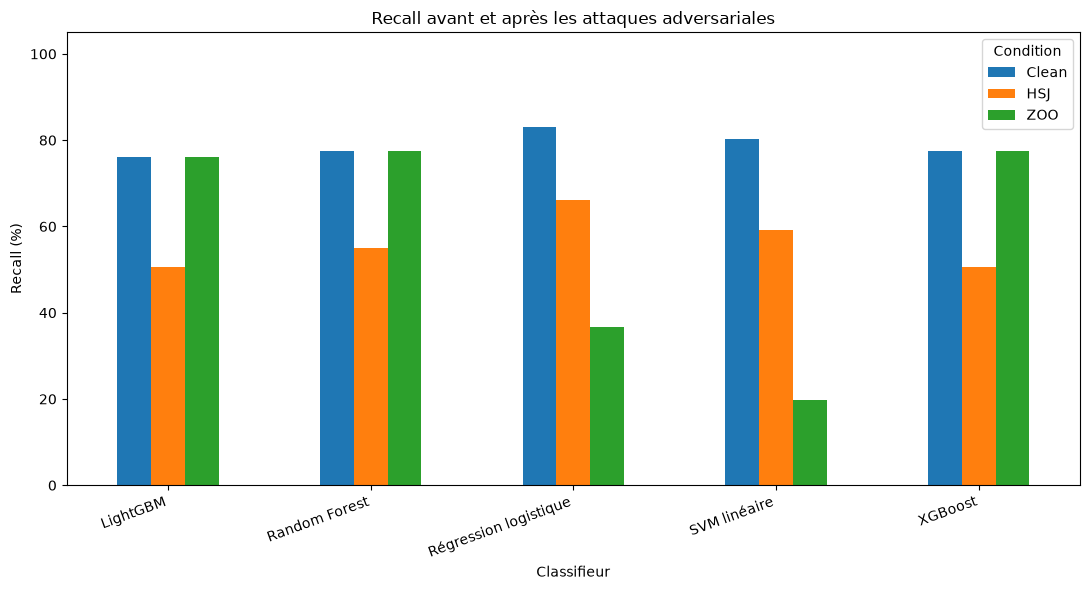

In [90]:
# ============================================================
# ÉTAPE 25 — RECALL CLEAN / ZOO / HSJ
# ============================================================

import matplotlib.pyplot as plt


recall_plot = (
    clean_vs_attacks_df
    .pivot(
        index="Model",
        columns="Condition",
        values="Recall"
    )
    *
    100
)


ax = recall_plot.plot(
    kind="bar",
    figsize=(11, 6)
)


ax.set_title(
    "Recall avant et après les attaques adversariales"
)

ax.set_xlabel(
    "Classifieur"
)

ax.set_ylabel(
    "Recall (%)"
)

ax.set_ylim(
    0,
    105
)


plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()


plt.savefig(
    FINAL_DIR
    /
    "figure_recall_clean_zoo_hsj.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [89]:
# ============================================================
# ÉTAPE 24 — VALIDATION DES PERTURBATIONS
# ============================================================

perturbation_rows = []


for (
    attack_name,
    model_name
), group in (
    all_attack_results
    .groupby(
        [
            "Attack",
            "Model"
        ]
    )
):

    successful = group[
        group[
            "Success"
        ] == 1
    ]


    perturbation_rows.append(
        {

            "Attack":
                attack_name,

            "Model":
                model_name,

            "Mean_L2_All":
                group["L2"].mean(),

            "Mean_Linf_All":
                group["Linf"].mean(),

            "Max_Linf_All":
                group["Linf"].max(),

            "Mean_L2_Success":
                (
                    successful["L2"].mean()
                    if len(successful) > 0
                    else np.nan
                ),

            "Mean_Linf_Success":
                (
                    successful["Linf"].mean()
                    if len(successful) > 0
                    else np.nan
                ),

            "Max_Linf_Success":
                (
                    successful["Linf"].max()
                    if len(successful) > 0
                    else np.nan
                )
        }
    )


perturbation_df = pd.DataFrame(
    perturbation_rows
)


display(
    perturbation_df.round(4)
)


# ------------------------------------------------------------
# Contrôle spécifique HSJ
# ------------------------------------------------------------

successful_hsj = (
    hsj_test_df[
        hsj_test_df[
            "Local_Success"
        ] == 1
    ]
)


if len(successful_hsj) > 0:

    assert (
        successful_hsj[
            "Linf"
        ].max()
        <=
        HSJ_LOCAL_EPS + 1e-8
    )


assert (
    hsj_test_df[
        "Max_Immutable_Change"
    ].max()
    <=
    1e-8
)


print("✅ Contraintes HSJ respectées.")

,Attack,Model,Mean_L2_All,Mean_Linf_All,Max_Linf_All,Mean_L2_Success,Mean_Linf_Success,Max_Linf_Success
0,HSJ,LightGBM,0.2662,0.0814,0.3725,0.1096,0.0320,0.0484
1,HSJ,Random Forest,0.3178,0.0952,0.3099,0.1166,0.0330,0.0489
2,HSJ,Régression logistique,0.5200,0.1047,0.2775,0.1756,0.0352,0.0493
3,HSJ,SVM linéaire,0.4173,0.0857,0.2246,0.1541,0.0316,0.0490
4,HSJ,XGBoost,0.3137,0.0962,0.4380,0.1110,0.0335,0.0480
5,ZOO,LightGBM,0.0001,0.0001,0.0045,NaN,NaN,NaN
6,ZOO,Random Forest,0.0001,0.0001,0.0045,NaN,NaN,NaN
7,ZOO,Régression logistique,0.1704,0.0992,0.2558,0.2736,0.1593,0.2558
8,ZOO,SVM linéaire,0.2951,0.1390,0.3440,0.2458,0.1189,0.2516
9,ZOO,XGBoost,0.0001,0.0001,0.0045,NaN,NaN,NaN


✅ Contraintes HSJ respectées.


In [88]:
# ============================================================
# ÉTAPE 23 — ASR + INTERVALLE DE CONFIANCE DE WILSON
# ============================================================

def wilson_interval(
    successes,
    n,
    z=1.96
):

    if n == 0:
        return np.nan, np.nan


    p = successes / n


    denominator = (
        1
        +
        z**2 / n
    )


    centre = (
        p
        +
        z**2 / (2 * n)
    )


    margin = (
        z
        *
        np.sqrt(
            (
                p * (1 - p)
                +
                z**2 / (4 * n)
            )
            /
            n
        )
    )


    low = (
        centre - margin
    ) / denominator


    high = (
        centre + margin
    ) / denominator


    return low, high


asr_rows = []


for (
    attack_name,
    model_name
), group in (
    all_attack_results
    .groupby(
        [
            "Attack",
            "Model"
        ]
    )
):

    n = len(group)

    successes = int(
        group[
            "Success"
        ].sum()
    )


    low, high = wilson_interval(
        successes,
        n
    )


    asr_rows.append(
        {
            "Attack":
                attack_name,

            "Model":
                model_name,

            "Attacks":
                n,

            "Successful_Attacks":
                successes,

            "ASR":
                100 * successes / n,

            "CI95_Low":
                100 * low,

            "CI95_High":
                100 * high
        }
    )


asr_df = pd.DataFrame(
    asr_rows
)


asr_df.to_csv(
    FINAL_DIR
    /
    "asr_summary.csv",
    index=False
)


display(
    asr_df.round(2)
)

,Attack,Model,Attacks,Successful_Attacks,ASR,CI95_Low,CI95_High
0,HSJ,LightGBM,53,18,33.96,22.69,47.41
1,HSJ,Random Forest,53,16,30.19,19.52,43.54
2,HSJ,Régression logistique,53,12,22.64,13.45,35.53
3,HSJ,SVM linéaire,53,15,28.30,17.97,41.57
4,HSJ,XGBoost,53,19,35.85,24.30,49.31
5,ZOO,LightGBM,53,0,0.00,-0.00,6.76
6,ZOO,Random Forest,53,0,0.00,-0.00,6.76
7,ZOO,Régression logistique,53,33,62.26,48.81,74.06
8,ZOO,SVM linéaire,53,43,81.13,68.64,89.41
9,ZOO,XGBoost,53,0,0.00,-0.00,6.76


In [87]:
# ============================================================
# ÉTAPE 22 — CLEAN VS ZOO VS HSJ
# ============================================================

evaluation_rows = []


for model_name in REFERENCE_MODEL_ORDER:

    model = models[
        model_name
    ]


    # CLEAN
    clean_metrics = (
        evaluate_model_dataset(
            model,
            X_test,
            y_test
        )
    )


    evaluation_rows.append(
        {
            "Model":
                model_name,

            "Condition":
                "Clean",

            **clean_metrics
        }
    )


    # ZOO
    zoo_metrics = (
        evaluate_model_dataset(
            model,
            X_TEST_ADV[
                "ZOO"
            ][model_name],
            y_test
        )
    )


    evaluation_rows.append(
        {
            "Model":
                model_name,

            "Condition":
                "ZOO",

            **zoo_metrics
        }
    )


    # HSJ LOCAL
    hsj_metrics = (
        evaluate_model_dataset(
            model,
            X_TEST_ADV[
                "HSJ"
            ][model_name],
            y_test
        )
    )


    evaluation_rows.append(
        {
            "Model":
                model_name,

            "Condition":
                "HSJ",

            **hsj_metrics
        }
    )


clean_vs_attacks_df = pd.DataFrame(
    evaluation_rows
)


clean_vs_attacks_df.to_csv(
    FINAL_DIR
    /
    "clean_vs_attacks_metrics.csv",
    index=False
)


display(
    clean_vs_attacks_df.round(4)
)

,Model,Condition,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP
0,XGBoost,Clean,0.9993,0.8209,0.7746,0.7971,0.9748,42476,12,16,55
1,XGBoost,ZOO,0.9993,0.8209,0.7746,0.7971,0.9748,42476,12,16,55
2,XGBoost,HSJ,0.9989,0.7500,0.5070,0.6050,0.9747,42476,12,35,36
3,Random Forest,Clean,0.9995,0.9016,0.7746,0.8333,0.9847,42482,6,16,55
4,Random Forest,ZOO,0.9995,0.9016,0.7746,0.8333,0.9847,42482,6,16,55
5,Random Forest,HSJ,0.9991,0.8667,0.5493,0.6724,0.9847,42482,6,32,39
6,LightGBM,Clean,0.9994,0.8710,0.7606,0.8120,0.9698,42480,8,17,54
7,LightGBM,ZOO,0.9994,0.8710,0.7606,0.8120,0.9698,42480,8,17,54
8,LightGBM,HSJ,0.9990,0.8182,0.5070,0.6261,0.9697,42480,8,35,36
9,SVM linéaire,Clean,0.9988,0.6196,0.8028,0.6994,0.9564,42453,35,14,57


In [86]:
# ============================================================
# ÉTAPE 21 — FONCTION D'ÉVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


def evaluate_model_dataset(
    model,
    X,
    y
):

    y_true = (
        np.asarray(y)
        .reshape(-1)
        .astype(int)
    )


    scores = (
        get_two_class_scores_reference(
            model,
            X
        )
    )


    y_pred = np.argmax(
        scores,
        axis=1
    )


    fraud_scores = (
        scores[:, 1]
    )


    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )
        .ravel()
    )


    return {

        "Accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "Precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_true,
                fraud_scores
            ),

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


print("✅ Fonction d'évaluation prête.")

✅ Fonction d'évaluation prête.


In [85]:
# ============================================================
# ÉTAPE 20 — CONSTRUCTION DES DATASETS ADVERSARIAUX
# ============================================================

DATASET_DIR = FINAL_DIR / "datasets"
DATASET_DIR.mkdir(exist_ok=True)


ZOO_ADV_DIR = Path(
    "zoo_test_final/adversarial_samples"
)


# ------------------------------------------------------------
# Dictionnaire final
# ------------------------------------------------------------

X_TEST_ADV = {
    "ZOO": {},
    "HSJ": {}
}


# ============================================================
# ZOO
# ============================================================

for model_name in REFERENCE_MODEL_ORDER:

    X_adv_zoo = X_test.copy(
        deep=True
    )


    for position in common_test_fraud_positions:

        position = int(position)


        sample_file = (
            ZOO_ADV_DIR
            /
            f"{MODEL_SLUG[model_name]}_{position}.npy"
        )


        if not sample_file.exists():

            raise FileNotFoundError(
                f"x_adv ZOO manquant : {sample_file}"
            )


        x_adv = np.load(
            sample_file
        )


        X_adv_zoo.iloc[
            position,
            :
        ] = x_adv


    X_TEST_ADV[
        "ZOO"
    ][model_name] = X_adv_zoo


    X_adv_zoo.to_csv(
        DATASET_DIR
        /
        f"X_test_zoo_{MODEL_SLUG[model_name]}.csv",
        index=False
    )


# ============================================================
# HSJ LOCAL
# ============================================================

for model_name in REFERENCE_MODEL_ORDER:

    X_adv_hsj = X_test.copy(
        deep=True
    )


    model_hsj = (
        hsj_test_df[
            hsj_test_df[
                "Model"
            ]
            ==
            model_name
        ]
    )


    successful_positions = set(
        model_hsj.loc[
            model_hsj[
                "Local_Success"
            ] == 1,
            "Transaction"
        ]
        .astype(int)
        .tolist()
    )


    for position in successful_positions:

        sample_file = (
            HSJ_TEST_ADV_DIR
            /
            f"{MODEL_SLUG[model_name]}_{position}.npy"
        )


        if not sample_file.exists():

            raise FileNotFoundError(
                f"x_adv HSJ manquant : {sample_file}"
            )


        x_adv = np.load(
            sample_file
        )


        X_adv_hsj.iloc[
            position,
            :
        ] = x_adv


    X_TEST_ADV[
        "HSJ"
    ][model_name] = X_adv_hsj


    X_adv_hsj.to_csv(
        DATASET_DIR
        /
        f"X_test_hsj_{MODEL_SLUG[model_name]}.csv",
        index=False
    )


# ------------------------------------------------------------
# Clean + labels
# ------------------------------------------------------------

X_test.to_csv(
    DATASET_DIR
    /
    "X_test_clean.csv",
    index=False
)


pd.DataFrame(
    {
        "Class":
            np.asarray(
                y_test
            ).reshape(-1)
    }
).to_csv(
    DATASET_DIR
    /
    "y_test.csv",
    index=False
)


print("✅ Datasets adversariaux construits.")

✅ Datasets adversariaux construits.


In [84]:
# ============================================================
# ÉTAPE 19 — CONSOLIDATION ZOO + HSJ
# ============================================================

FINAL_DIR = Path("notebook10_final")
FINAL_DIR.mkdir(exist_ok=True)


# ------------------------------------------------------------
# Charger ZOO
# ------------------------------------------------------------

ZOO_RESULTS_FILE = Path(
    "zoo_test_final/zoo_test_individual_results.csv"
)


if not ZOO_RESULTS_FILE.exists():
    raise FileNotFoundError(
        f"Fichier ZOO introuvable : {ZOO_RESULTS_FILE}"
    )


zoo_final_df = pd.read_csv(
    ZOO_RESULTS_FILE
)


# ------------------------------------------------------------
# Uniformiser le critère de succès
# ------------------------------------------------------------

zoo_standard = zoo_final_df.copy()

zoo_standard["Attack"] = "ZOO"

zoo_standard["Success"] = (
    zoo_standard[
        "Attack_Success"
    ].astype(int)
)

zoo_standard["Query_Count"] = (
    zoo_standard["Queries"]
)


# ------------------------------------------------------------
# HSJ
# ------------------------------------------------------------

hsj_standard = hsj_test_df.copy()

hsj_standard["Attack"] = "HSJ"

# IMPORTANT :
# pour HSJ, notre succès principal = Local_Success
hsj_standard["Success"] = (
    hsj_standard[
        "Local_Success"
    ].astype(int)
)

hsj_standard["Query_Count"] = (
    hsj_standard[
        "Total_Queries"
    ]
)


# ------------------------------------------------------------
# Colonnes communes
# ------------------------------------------------------------

COMMON_COLUMNS = [
    "Attack",
    "Model",
    "Transaction",
    "Success",
    "L2",
    "Linf",
    "Query_Count",
    "Time_s"
]


all_attack_results = pd.concat(
    [
        zoo_standard[
            COMMON_COLUMNS
        ],
        hsj_standard[
            COMMON_COLUMNS
        ]
    ],
    ignore_index=True
)


all_attack_results.to_csv(
    FINAL_DIR
    /
    "all_attack_results.csv",
    index=False
)


print(
    "ZOO :",
    len(zoo_standard)
)

print(
    "HSJ :",
    len(hsj_standard)
)

print(
    "Total :",
    len(all_attack_results)
)


assert len(zoo_standard) == 265
assert len(hsj_standard) == 265
assert len(all_attack_results) == 530


print("✅ 530 résultats consolidés")

ZOO : 265
HSJ : 265
Total : 530
✅ 530 résultats consolidés


In [83]:
# ============================================================
# ÉTAPE 18D — RÉSUMÉ FINAL HSJ SUR TEST
# ============================================================

hsj_test_summary = (
    hsj_test_df
    .groupby("Model")
    .agg(

        Attaques=(
            "Local_Success",
            "count"
        ),

        Succes_valides=(
            "Local_Success",
            "sum"
        ),

        Linf_moyen=(
            "Linf",
            "mean"
        ),

        Temps_moyen_s=(
            "Time_s",
            "mean"
        ),

        Requetes_moyennes=(
            "Total_Queries",
            "mean"
        )
    )
    .reset_index()
)


hsj_test_summary[
    "ASR_local"
] = (
    100
    *
    hsj_test_summary[
        "Succes_valides"
    ]
    /
    hsj_test_summary[
        "Attaques"
    ]
)


hsj_test_summary = (
    hsj_test_summary.rename(
        columns={
            "Model": "Modèle",
            "Succes_valides": "Succès valides",
            "ASR_local": "ASR local"
        }
    )
)


display(
    hsj_test_summary.style.format(
        {
            "ASR local": "{:.2f} %",
            "Linf_moyen": "{:.4f}",
            "Temps_moyen_s": "{:.2f}",
            "Requetes_moyennes": "{:.0f}"
        }
    )
)

,Modèle,Attaques,Succès valides,Linf_moyen,Temps_moyen_s,Requetes_moyennes,ASR local
0,LightGBM,53,18,0.0814,1.24,24849,33.96 %
1,Random Forest,53,16,0.0952,31.11,24841,30.19 %
2,Régression logistique,53,12,0.1047,0.81,24792,22.64 %
3,SVM linéaire,53,15,0.0857,0.83,24792,28.30 %
4,XGBoost,53,19,0.0962,2.48,24853,35.85 %


In [82]:
# ============================================================
# ÉTAPE 18C — CONTRÔLE DU TEST FINAL HSJ
# ============================================================

hsj_test_df = pd.read_csv(
    HSJ_TEST_RESULTS_FILE
)


print(
    "Nombre total d'attaques :",
    len(hsj_test_df),
    "/ 265"
)


print("\nAttaques par modèle :")

display(
    hsj_test_df
    .groupby("Model")
    .size()
    .rename("Nombre")
    .to_frame()
)


print(
    "\nSeeds valides :",
    int(hsj_test_df["Seed_Found"].sum()),
    "/",
    len(hsj_test_df)
)


print(
    "Modification maximale Time/Amount :",
    hsj_test_df[
        "Max_Immutable_Change"
    ].max()
)

Nombre total d'attaques : 265 / 265

Attaques par modèle :


,Nombre
Model,
LightGBM,53
Random Forest,53
Régression logistique,53
SVM linéaire,53
XGBoost,53



Seeds valides : 265 / 265
Modification maximale Time/Amount : 0.0


In [80]:
# ============================================================
# 18C — RÉSUMÉ FINAL HSJ SUR LES 53 TRANSACTIONS TEST
# ============================================================

import pandas as pd
import numpy as np

# Charger les résultats
hsj_test_df = pd.read_csv(HSJ_TEST_RESULTS_FILE)

EXPECTED_TRANSACTIONS = 53
EXPECTED_MODELS = 5
EXPECTED_TOTAL = EXPECTED_TRANSACTIONS * EXPECTED_MODELS

print("=" * 75)
print("RÉSUMÉ HSJ — TEST FINAL")
print("=" * 75)

print(f"Résultats enregistrés : {len(hsj_test_df)} / {EXPECTED_TOTAL}")
print(f"Transactions attendues : {EXPECTED_TRANSACTIONS}")
print(f"Modèles : {EXPECTED_MODELS}")

# ------------------------------------------------------------
# Résumé par modèle
# ------------------------------------------------------------

summary_hsj_test = (
    hsj_test_df
    .groupby("Model")
    .agg(
        Attaques=("Transaction", "count"),
        Succes_bruts=("Raw_Success", "sum"),
        Succes_valides=("Local_Success", "sum"),
        L2_moyen=("L2", "mean"),
        Linf_moyen=("Linf", "mean"),
        Linf_min=("Linf", "min"),
        Linf_max=("Linf", "max"),
        Queries_moyennes=("Total_Queries", "mean"),
        Temps_moyen_s=("Time_s", "mean"),
        Temps_total_min=("Time_s", lambda x: x.sum() / 60),
        Max_Immutable_Change=("Max_Immutable_Change", "max"),
    )
    .reset_index()
)

summary_hsj_test["ASR_brut_%"] = (
    100 * summary_hsj_test["Succes_bruts"] / summary_hsj_test["Attaques"]
)

summary_hsj_test["ASR_local_%"] = (
    100 * summary_hsj_test["Succes_valides"] / summary_hsj_test["Attaques"]
)

# Réorganisation
summary_hsj_test = summary_hsj_test[
    [
        "Model",
        "Attaques",
        "Succes_bruts",
        "Succes_valides",
        "ASR_brut_%",
        "ASR_local_%",
        "L2_moyen",
        "Linf_moyen",
        "Linf_min",
        "Linf_max",
        "Queries_moyennes",
        "Temps_moyen_s",
        "Temps_total_min",
        "Max_Immutable_Change",
    ]
]

print("\n")
display(
    summary_hsj_test.style.format({
        "ASR_brut_%": "{:.2f}%",
        "ASR_local_%": "{:.2f}%",
        "L2_moyen": "{:.4f}",
        "Linf_moyen": "{:.4f}",
        "Linf_min": "{:.4f}",
        "Linf_max": "{:.4f}",
        "Queries_moyennes": "{:.0f}",
        "Temps_moyen_s": "{:.2f}",
        "Temps_total_min": "{:.2f}",
        "Max_Immutable_Change": "{:.8f}",
    })
)

# ------------------------------------------------------------
# Contrôles méthodologiques
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONTRÔLES")
print("=" * 75)

print(
    f"Nombre total de résultats : "
    f"{len(hsj_test_df)} / {EXPECTED_TOTAL}"
)

print(
    "Nombre de transactions par modèle :",
    hsj_test_df.groupby("Model")["Transaction"].count().to_dict()
)

print(
    "Seeds trouvés :",
    f"{int(hsj_test_df['Seed_Found'].sum())} / {len(hsj_test_df)}"
)

print(
    "Modification maximale Time/Amount :",
    hsj_test_df["Max_Immutable_Change"].max()
)

# Vérifier les succès locaux
local_success_df = hsj_test_df[
    hsj_test_df["Local_Success"] == 1
]

if len(local_success_df) > 0:
    print(
        "Linf maximal parmi les succès locaux :",
        round(local_success_df["Linf"].max(), 6)
    )

    print(
        "Tous les succès locaux respectent Linf <= 0.05 :",
        bool(
            (
                local_success_df["Linf"]
                <= HSJ_LOCAL_EPS + 1e-8
            ).all()
        )
    )
else:
    print("Aucun succès local enregistré.")

print("=" * 75)

RÉSUMÉ HSJ — TEST FINAL
Résultats enregistrés : 265 / 265
Transactions attendues : 53
Modèles : 5




,Model,Attaques,Succes_bruts,Succes_valides,ASR_brut_%,ASR_local_%,L2_moyen,Linf_moyen,Linf_min,Linf_max,Queries_moyennes,Temps_moyen_s,Temps_total_min,Max_Immutable_Change
0,LightGBM,53,53,18,100.00%,33.96%,0.2662,0.0814,0.0096,0.3725,24849,1.24,1.10,0.00000000
1,Random Forest,53,53,16,100.00%,30.19%,0.3178,0.0952,0.0059,0.3099,24841,31.11,27.48,0.00000000
2,Régression logistique,53,53,12,100.00%,22.64%,0.5200,0.1047,0.0218,0.2775,24792,0.81,0.72,0.00000000
3,SVM linéaire,53,53,15,100.00%,28.30%,0.4173,0.0857,0.0140,0.2246,24792,0.83,0.73,0.00000000
4,XGBoost,53,53,19,100.00%,35.85%,0.3137,0.0962,0.0145,0.4380,24853,2.48,2.19,0.00000000



CONTRÔLES
Nombre total de résultats : 265 / 265
Nombre de transactions par modèle : {'LightGBM': 53, 'Random Forest': 53, 'Régression logistique': 53, 'SVM linéaire': 53, 'XGBoost': 53}
Seeds trouvés : 265 / 265
Modification maximale Time/Amount : 0.0
Linf maximal parmi les succès locaux : 0.049286
Tous les succès locaux respectent Linf <= 0.05 : True


In [79]:
# ============================================================
# ÉTAPE 18B — HSJ FINAL : 53 FRAUDES × 5 MODÈLES
# ============================================================

# ------------------------------------------------------------
# Reprendre une exécution précédente si elle existe
# ------------------------------------------------------------

if HSJ_TEST_RESULTS_FILE.exists():

    hsj_test_results = (
        pd.read_csv(HSJ_TEST_RESULTS_FILE)
        .to_dict("records")
    )

    print(
        "Reprise d'une exécution précédente :",
        len(hsj_test_results),
        "résultats trouvés."
    )

else:

    hsj_test_results = []


completed_pairs = {
    (
        row["Model"],
        int(row["Transaction"])
    )
    for row in hsj_test_results
}


TOTAL_HSJ_TEST_ATTACKS = (
    len(HSJ_TEST_POSITIONS)
    *
    len(REFERENCE_MODEL_ORDER)
)


print("Total attendu :", TOTAL_HSJ_TEST_ATTACKS)
print("Déjà terminées :", len(completed_pairs))
print(
    "Restantes :",
    TOTAL_HSJ_TEST_ATTACKS - len(completed_pairs)
)


global_start = time.time()


# ============================================================
# BOUCLE PRINCIPALE
# ============================================================

for transaction_number, position in enumerate(
    HSJ_TEST_POSITIONS,
    start=1
):

    print("\n" + "=" * 78)

    print(
        f"TRANSACTION {transaction_number}/"
        f"{len(HSJ_TEST_POSITIONS)}"
        f" — position Test = {position}"
    )

    print("=" * 78)


    x_attack = (
        X_test
        .iloc[position]
        .to_numpy(dtype=np.float32)
    )


    for model_index, model_name in enumerate(
        REFERENCE_MODEL_ORDER
    ):

        pair = (
            model_name,
            position
        )


        sample_file = (
            HSJ_TEST_ADV_DIR
            /
            f"{MODEL_SLUG[model_name]}_{position}.npy"
        )


        # ----------------------------------------------------
        # Déjà terminé ET x_adv bien sauvegardé
        # ----------------------------------------------------

        if (
            pair in completed_pairs
            and sample_file.exists()
        ):

            print(
                model_name,
                "→ déjà calculé ✅"
            )

            continue


        # Si le CSV contient la ligne mais que x_adv manque,
        # on enlève l'ancienne ligne et on recalcule proprement.
        if (
            pair in completed_pairs
            and not sample_file.exists()
        ):

            hsj_test_results = [
                row
                for row in hsj_test_results
                if not (
                    row["Model"] == model_name
                    and
                    int(row["Transaction"]) == position
                )
            ]

            completed_pairs.discard(pair)


        print("\nModèle :", model_name)


        # ----------------------------------------------------
        # Attaque avec EXACTEMENT la configuration validée
        # ----------------------------------------------------

        result = attack_one_transaction_hsj(
            models[model_name],
            x_attack,
            random_seed=(
                2026
                + position
                + model_index
            )
        )


        # ----------------------------------------------------
        # Sauvegarder x_adv
        # ----------------------------------------------------

        np.save(
            sample_file,
            result["x_adv"][0]
        )


        # ----------------------------------------------------
        # Résultat individuel
        # ----------------------------------------------------

        row = {

            "Model":
                model_name,

            "Transaction":
                position,

            "Clean_Pred":
                result["Clean_Pred"],

            "Adv_Pred":
                result["Adv_Pred"],

            # HSJ a-t-il obtenu 1 -> 0,
            # indépendamment de la distance ?
            "Raw_Success":
                result["Raw_Success"],

            # Résultat PRINCIPAL :
            # 1 -> 0 ET Linf <= 0.05
            "Local_Success":
                result["Local_Success"],

            "L2":
                result["L2"],

            "Linf":
                result["Linf"],

            "Max_Immutable_Change":
                result["Max_Immutable_Change"],

            "Seed_Found":
                result["Seed_Found"],

            "Seed_Queries":
                result["Seed_Queries"],

            "HSJ_Queries":
                result["HSJ_Queries"],

            "Total_Queries":
                result["Total_Queries"],

            "Time_s":
                result["Time_s"]
        }


        hsj_test_results.append(row)
        completed_pairs.add(pair)


        # ----------------------------------------------------
        # Sauvegarde APRÈS CHAQUE attaque
        # ----------------------------------------------------

        pd.DataFrame(
            hsj_test_results
        ).to_csv(
            HSJ_TEST_RESULTS_FILE,
            index=False
        )


        print(
            "Avant :",
            result["Clean_Pred"],
            "| Après :",
            result["Adv_Pred"]
        )

        print(
            "Linf :",
            round(result["Linf"], 4),
            "| limite locale :",
            HSJ_LOCAL_EPS
        )

        print(
            "Succès local :",
            bool(result["Local_Success"])
        )

        print(
            "Temps :",
            round(result["Time_s"], 2),
            "s"
        )


    print(
        "\nProgression :",
        len(completed_pairs),
        "/",
        TOTAL_HSJ_TEST_ATTACKS
    )


elapsed = time.time() - global_start


print("\n" + "=" * 78)
print("✅ HSJ FINAL SUR TEST TERMINÉ")
print("=" * 78)

print(
    "Résultats :",
    len(completed_pairs),
    "/",
    TOTAL_HSJ_TEST_ATTACKS
)

print(
    "Temps supplémentaire :",
    round(elapsed / 60, 2),
    "minutes"
)

Total attendu : 265
Déjà terminées : 0
Restantes : 265

TRANSACTION 1/53 — position Test = 304

Modèle : XGBoost
Avant : 1 | Après : 0
Linf : 0.0792 | limite locale : 0.05
Succès local : False
Temps : 2.39 s

Modèle : Random Forest
Avant : 1 | Après : 0
Linf : 0.085 | limite locale : 0.05
Succès local : False
Temps : 30.43 s

Modèle : LightGBM
Avant : 1 | Après : 0
Linf : 0.067 | limite locale : 0.05
Succès local : False
Temps : 1.44 s

Modèle : SVM linéaire
Avant : 1 | Après : 0
Linf : 0.0637 | limite locale : 0.05
Succès local : False
Temps : 0.88 s

Modèle : Régression logistique
Avant : 1 | Après : 0
Linf : 0.0748 | limite locale : 0.05
Succès local : False
Temps : 0.79 s

Progression : 5 / 265

TRANSACTION 2/53 — position Test = 1252

Modèle : XGBoost
Avant : 1 | Après : 0
Linf : 0.027 | limite locale : 0.05
Succès local : True
Temps : 2.84 s

Modèle : Random Forest
Avant : 1 | Après : 0
Linf : 0.04 | limite locale : 0.05
Succès local : True
Temps : 31.0 s

Modèle : LightGBM
Avant

In [78]:
# ============================================================
# ÉTAPE 18A — PRÉPARATION HSJ FINAL SUR TEST
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import time


HSJ_TEST_DIR = Path("hsj_experiment_b_v2/test_final")
HSJ_TEST_ADV_DIR = HSJ_TEST_DIR / "adversarial_samples"

HSJ_TEST_DIR.mkdir(parents=True, exist_ok=True)
HSJ_TEST_ADV_DIR.mkdir(parents=True, exist_ok=True)


HSJ_TEST_RESULTS_FILE = (
    HSJ_TEST_DIR
    / "hsj_test_individual_results.csv"
)


MODEL_SLUG = {
    "XGBoost": "xgboost",
    "Random Forest": "random_forest",
    "LightGBM": "lightgbm",
    "SVM linéaire": "svm_lineaire",
    "Régression logistique": "regression_logistique"
}


# ------------------------------------------------------------
# Les 53 positions du Test trouvées à l'étape 16
# ------------------------------------------------------------

HSJ_TEST_POSITIONS = [
    int(position)
    for position in common_test_fraud_positions
]


print("Fraudes communes du Test :", len(HSJ_TEST_POSITIONS))
print(
    "Nombre total d'attaques :",
    len(HSJ_TEST_POSITIONS) * len(REFERENCE_MODEL_ORDER)
)


assert len(HSJ_TEST_POSITIONS) == 53, (
    "Attention : on attend 53 fraudes communes sur le Test."
)

Fraudes communes du Test : 53
Nombre total d'attaques : 265


# Étape 18 — Évaluation finale de HopSkipJump sur le jeu de Test

La configuration de HopSkipJump ayant été validée sur le jeu de Validation,
elle est désormais figée.

L'évaluation finale est réalisée sur les 53 transactions frauduleuses du jeu
de Test correctement détectées par les cinq modèles.

Une attaque HSJ est considérée comme localement réussie lorsque :

- la transaction est initialement prédite comme frauduleuse ;
- après perturbation, elle est prédite comme normale ;
- la distance L∞ entre l'exemple original et l'exemple adversarial est ≤ 0.05 ;
- les variables Time et Amount restent inchangées.

Le jeu de Test n'est utilisé que pour l'évaluation finale et aucun paramètre
de l'attaque n'est ajusté à partir de ses résultats.

In [77]:
HSJ_LOCAL_EPS = 0.05

HSJ_CONFIG = {
    "targeted": True,
    "norm": np.inf,
    "max_iter": 50,
    "max_eval": 10000,
    "init_eval": 100,
    "init_size": 100,
    "batch_size": 64,
    "verbose": False
}

In [76]:
# ============================================================
# B.11 — RÉSUMÉ FINAL VALIDATION — 20 TRANSACTIONS
# ============================================================

hsj_val20_df = pd.DataFrame(
    hsj_val20_results
)


hsj_val20_summary = (
    hsj_val20_df
    .groupby(
        "Model"
    )
    .agg(

        Attaques=(
            "Local_Success",
            "count"
        ),

        Succes_valides=(
            "Local_Success",
            "sum"
        ),

        Linf_moyen=(
            "Linf",
            "mean"
        ),

        Temps_moyen_s=(
            "Time_s",
            "mean"
        )
    )
    .reset_index()
)


hsj_val20_summary[
    "ASR_Local"
] = (
    100
    *
    hsj_val20_summary[
        "Succes_valides"
    ]
    /
    hsj_val20_summary[
        "Attaques"
    ]
)


hsj_val20_summary = (
    hsj_val20_summary
    .rename(
        columns={
            "Model":
                "Modèle",

            "Succes_valides":
                "Succès valides",

            "ASR_Local":
                "ASR local"
        }
    )
)


display(
    hsj_val20_summary.style.format(
        {
            "ASR local":
                "{:.1f} %",

            "Linf_moyen":
                "{:.4f}",

            "Temps_moyen_s":
                "{:.2f}"
        }
    )
)

,Modèle,Attaques,Succès valides,Linf_moyen,Temps_moyen_s,ASR local
0,LightGBM,20,10,0.0566,1.27,50.0 %
1,Random Forest,20,6,0.0877,30.79,30.0 %
2,Régression logistique,20,5,0.0969,0.79,25.0 %
3,SVM linéaire,20,6,0.0787,0.81,30.0 %
4,XGBoost,20,6,0.0830,2.51,30.0 %


In [75]:
# ============================================================
# B.10 — HSJ SUR 20 TRANSACTIONS DE VALIDATION
# ============================================================

HSJ_VAL20_POSITIONS = [
    int(position)
    for position
    in HSJ_VAL_COMMON_FRAUDS[:20]
]


HSJ_VAL20_FILE = (
    HSJ_B_DIR
    /
    "validation_20_results.csv"
)


# ------------------------------------------------------------
# Reprise
# ------------------------------------------------------------

if HSJ_VAL20_FILE.exists():

    hsj_val20_results = (
        pd.read_csv(
            HSJ_VAL20_FILE
        )
        .to_dict("records")
    )

else:

    # Réutiliser les 5 premières
    pilot_df_copy = (
        hsj_pilot_df[
            hsj_pilot_df[
                "Transaction"
            ]
            .astype(int)
            .isin(
                HSJ_VAL20_POSITIONS
            )
        ]
        .copy()
    )


    hsj_val20_results = (
        pilot_df_copy
        .to_dict("records")
    )


    pd.DataFrame(
        hsj_val20_results
    ).to_csv(
        HSJ_VAL20_FILE,
        index=False
    )


completed = {
    (
        row["Model"],
        int(row["Transaction"])
    )
    for row
    in hsj_val20_results
}


TOTAL_EXPECTED = (
    20
    *
    len(REFERENCE_MODEL_ORDER)
)


print(
    "Total attendu :",
    TOTAL_EXPECTED
)

print(
    "Déjà terminé :",
    len(completed)
)

print(
    "Restant :",
    TOTAL_EXPECTED
    -
    len(completed)
)


global_start = time.time()


for transaction_number, position in enumerate(
    HSJ_VAL20_POSITIONS,
    start=1
):

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"TRANSACTION "
        f"{transaction_number}/20"
        f" — position {position}"
    )

    print(
        "=" * 70
    )


    x_attack = (
        X_val
        .iloc[position]
        .to_numpy(
            dtype=np.float32
        )
    )


    for model_index, model_name in enumerate(
        REFERENCE_MODEL_ORDER
    ):

        pair = (
            model_name,
            position
        )


        if pair in completed:

            print(
                model_name,
                "→ déjà calculé ✅"
            )

            continue


        result = (
            attack_one_transaction_hsj(
                models[
                    model_name
                ],
                x_attack,
                random_seed=(
                    2026
                    +
                    position
                    +
                    model_index
                )
            )
        )


        row = {

            "Model":
                model_name,

            "Transaction":
                position,

            "Clean_Pred":
                result[
                    "Clean_Pred"
                ],

            "Adv_Pred":
                result[
                    "Adv_Pred"
                ],

            "Raw_Success":
                result[
                    "Raw_Success"
                ],

            "Local_Success":
                result[
                    "Local_Success"
                ],

            "L2":
                result[
                    "L2"
                ],

            "Linf":
                result[
                    "Linf"
                ],

            "Max_Immutable_Change":
                result[
                    "Max_Immutable_Change"
                ],

            "Seed_Found":
                result[
                    "Seed_Found"
                ],

            "Seed_Queries":
                result[
                    "Seed_Queries"
                ],

            "HSJ_Queries":
                result[
                    "HSJ_Queries"
                ],

            "Total_Queries":
                result[
                    "Total_Queries"
                ],

            "Time_s":
                result[
                    "Time_s"
                ]
        }


        hsj_val20_results.append(
            row
        )


        completed.add(
            pair
        )


        pd.DataFrame(
            hsj_val20_results
        ).to_csv(
            HSJ_VAL20_FILE,
            index=False
        )


        print(
            model_name,
            "→ Linf =",
            round(
                result["Linf"],
                4
            ),
            "| Succès local =",
            bool(
                result[
                    "Local_Success"
                ]
            )
        )


    print(
        "\nProgression :",
        len(completed),
        "/",
        TOTAL_EXPECTED
    )


elapsed = (
    time.time()
    -
    global_start
)


print(
    "\n✅ Validation 20 terminée"
)

print(
    "Temps supplémentaire :",
    round(
        elapsed / 60,
        2
    ),
    "minutes"
)

Total attendu : 100
Déjà terminé : 25
Restant : 75

TRANSACTION 1/20 — position 544
XGBoost → déjà calculé ✅
Random Forest → déjà calculé ✅
LightGBM → déjà calculé ✅
SVM linéaire → déjà calculé ✅
Régression logistique → déjà calculé ✅

Progression : 25 / 100

TRANSACTION 2/20 — position 666
XGBoost → déjà calculé ✅
Random Forest → déjà calculé ✅
LightGBM → déjà calculé ✅
SVM linéaire → déjà calculé ✅
Régression logistique → déjà calculé ✅

Progression : 25 / 100

TRANSACTION 3/20 — position 1899
XGBoost → déjà calculé ✅
Random Forest → déjà calculé ✅
LightGBM → déjà calculé ✅
SVM linéaire → déjà calculé ✅
Régression logistique → déjà calculé ✅

Progression : 25 / 100

TRANSACTION 4/20 — position 2897
XGBoost → déjà calculé ✅
Random Forest → déjà calculé ✅
LightGBM → déjà calculé ✅
SVM linéaire → déjà calculé ✅
Régression logistique → déjà calculé ✅

Progression : 25 / 100

TRANSACTION 5/20 — position 4127
XGBoost → déjà calculé ✅
Random Forest → déjà calculé ✅
LightGBM → déjà calculé ✅

In [74]:
# ============================================================
# B.9 — CONTRÔLES DU PILOTE
# ============================================================

print(
    "Nombre total d'attaques :",
    len(hsj_pilot_df),
    "/ 25"
)


print(
    "Seeds valides trouvés :",
    int(
        hsj_pilot_df[
            "Seed_Found"
        ].sum()
    ),
    "/",
    len(hsj_pilot_df)
)


print(
    "Modification maximale "
    "de Time/Amount :",
    hsj_pilot_df[
        "Max_Immutable_Change"
    ].max()
)


print(
    "Linf minimal observé :",
    hsj_pilot_df[
        "Linf"
    ].min()
)


print(
    "Linf maximal observé :",
    hsj_pilot_df[
        "Linf"
    ].max()
)

Nombre total d'attaques : 25 / 25
Seeds valides trouvés : 25 / 25
Modification maximale de Time/Amount : 0.0
Linf minimal observé : 0.01982492208480835
Linf maximal observé : 0.26377958059310913


In [73]:
# ============================================================
# B.8 — RÉSUMÉ SIMPLE — 5 TRANSACTIONS
# ============================================================

hsj_pilot_df = pd.DataFrame(
    hsj_pilot_results
)


hsj_pilot_summary = (
    hsj_pilot_df
    .groupby(
        "Model"
    )
    .agg(

        Attaques=(
            "Local_Success",
            "count"
        ),

        Succes_valides=(
            "Local_Success",
            "sum"
        )
    )
    .reset_index()
)


hsj_pilot_summary[
    "ASR_Local"
] = (
    100
    *
    hsj_pilot_summary[
        "Succes_valides"
    ]
    /
    hsj_pilot_summary[
        "Attaques"
    ]
)


hsj_pilot_summary = (
    hsj_pilot_summary
    .rename(
        columns={
            "Model":
                "Modèle",

            "Succes_valides":
                "Succès valides",

            "ASR_Local":
                "ASR local"
        }
    )
)


display(
    hsj_pilot_summary.style.format(
        {
            "ASR local":
                "{:.0f} %"
        }
    )
)

,Modèle,Attaques,Succès valides,ASR local
0,LightGBM,5,2,40 %
1,Random Forest,5,2,40 %
2,Régression logistique,5,1,20 %
3,SVM linéaire,5,1,20 %
4,XGBoost,5,1,20 %


In [72]:
# ============================================================
# B.7 — PILOTE HSJ — 5 TRANSACTIONS VALIDATION
# ============================================================

HSJ_PILOT_POSITIONS = [
    int(position)
    for position
    in HSJ_VAL_COMMON_FRAUDS[:5]
]


HSJ_PILOT_FILE = (
    HSJ_B_DIR
    /
    "validation_5_results.csv"
)


# Nouveau dossier = pas de mélange
if HSJ_PILOT_FILE.exists():

    hsj_pilot_results = (
        pd.read_csv(
            HSJ_PILOT_FILE
        )
        .to_dict("records")
    )

else:

    hsj_pilot_results = []


completed = {
    (
        row["Model"],
        int(row["Transaction"])
    )
    for row
    in hsj_pilot_results
}


print(
    "Positions :",
    HSJ_PILOT_POSITIONS
)

print(
    "Attaques prévues :",
    5 * len(REFERENCE_MODEL_ORDER)
)


for transaction_number, position in enumerate(
    HSJ_PILOT_POSITIONS,
    start=1
):

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"TRANSACTION "
        f"{transaction_number}/5"
        f" — position {position}"
    )

    print(
        "=" * 70
    )


    x_attack = (
        X_val
        .iloc[position]
        .to_numpy(
            dtype=np.float32
        )
    )


    for model_index, model_name in enumerate(
        REFERENCE_MODEL_ORDER
    ):

        pair = (
            model_name,
            position
        )


        if pair in completed:

            print(
                model_name,
                "→ déjà calculé ✅"
            )

            continue


        print(
            "\nModèle :",
            model_name
        )


        result = (
            attack_one_transaction_hsj(
                models[model_name],
                x_attack,
                random_seed=(
                    2026
                    +
                    position
                    +
                    model_index
                )
            )
        )


        row = {

            "Model":
                model_name,

            "Transaction":
                position,

            "Clean_Pred":
                result[
                    "Clean_Pred"
                ],

            "Adv_Pred":
                result[
                    "Adv_Pred"
                ],

            "Raw_Success":
                result[
                    "Raw_Success"
                ],

            "Local_Success":
                result[
                    "Local_Success"
                ],

            "L2":
                result[
                    "L2"
                ],

            "Linf":
                result[
                    "Linf"
                ],

            "Max_Immutable_Change":
                result[
                    "Max_Immutable_Change"
                ],

            "Seed_Found":
                result[
                    "Seed_Found"
                ],

            "Seed_Queries":
                result[
                    "Seed_Queries"
                ],

            "HSJ_Queries":
                result[
                    "HSJ_Queries"
                ],

            "Total_Queries":
                result[
                    "Total_Queries"
                ],

            "Time_s":
                result[
                    "Time_s"
                ]
        }


        hsj_pilot_results.append(
            row
        )


        completed.add(
            pair
        )


        pd.DataFrame(
            hsj_pilot_results
        ).to_csv(
            HSJ_PILOT_FILE,
            index=False
        )


        print(
            "Avant :",
            result["Clean_Pred"],
            "| Après :",
            result["Adv_Pred"]
        )


        print(
            "Linf :",
            round(
                result["Linf"],
                4
            ),

            "| Critère : <=",
            HSJ_LOCAL_EPS
        )


        print(
            "Succès local :",
            bool(
                result[
                    "Local_Success"
                ]
            )
        )


print(
    "\n✅ Pilote 5 terminé"
)

Positions : [544, 666, 1899, 2897, 4127]
Attaques prévues : 25

TRANSACTION 1/5 — position 544

Modèle : XGBoost
Avant : 1 | Après : 0
Linf : 0.1229 | Critère : <= 0.05
Succès local : False

Modèle : Random Forest
Avant : 1 | Après : 0
Linf : 0.0198 | Critère : <= 0.05
Succès local : True

Modèle : LightGBM
Avant : 1 | Après : 0
Linf : 0.1112 | Critère : <= 0.05
Succès local : False

Modèle : SVM linéaire
Avant : 1 | Après : 0
Linf : 0.0572 | Critère : <= 0.05
Succès local : False

Modèle : Régression logistique
Avant : 1 | Après : 0
Linf : 0.0895 | Critère : <= 0.05
Succès local : False

TRANSACTION 2/5 — position 666

Modèle : XGBoost
Avant : 1 | Après : 0
Linf : 0.179 | Critère : <= 0.05
Succès local : False

Modèle : Random Forest
Avant : 1 | Après : 0
Linf : 0.2004 | Critère : <= 0.05
Succès local : False

Modèle : LightGBM
Avant : 1 | Après : 0
Linf : 0.1793 | Critère : <= 0.05
Succès local : False

Modèle : SVM linéaire
Avant : 1 | Après : 0
Linf : 0.1663 | Critère : <= 0.05
Suc

In [71]:
# ============================================================
# B.6 — ATTAQUE HSJ DÉFINITIVE
# ============================================================

def attack_one_transaction_hsj(
    model,
    x_full,
    random_seed=2026
):

    x_clean = np.asarray(
        x_full,
        dtype=np.float32
    ).reshape(1, -1)


    # --------------------------------------------------------
    # 1. Prédiction originale
    # --------------------------------------------------------

    clean_scores = (
        get_two_class_scores_reference(
            model,
            pd.DataFrame(
                x_clean,
                columns=FEATURE_COLUMNS
            )
        )
    )


    clean_pred = int(
        np.argmax(
            clean_scores[0]
        )
    )


    if clean_pred != 1:
        raise ValueError(
            "La transaction n'est pas une fraude "
            "correctement détectée avant l'attaque."
        )


    # --------------------------------------------------------
    # 2. Trouver un seed NORMAL valide
    # --------------------------------------------------------

    x_init, seed_queries = (
        find_valid_hsj_seed(
            model,
            x_clean
        )
    )


    if x_init is None:

        return {

            "Clean_Pred":
                clean_pred,

            "Adv_Pred":
                clean_pred,

            "Raw_Success":
                0,

            "Local_Success":
                0,

            "L2":
                0.0,

            "Linf":
                0.0,

            "Max_Immutable_Change":
                0.0,

            "Seed_Found":
                0,

            "Seed_Queries":
                seed_queries,

            "HSJ_Queries":
                0,

            "Total_Queries":
                seed_queries,

            "Time_s":
                0.0,

            "x_adv":
                x_clean.copy()
        }


    # --------------------------------------------------------
    # 3. ART black-box
    # --------------------------------------------------------

    art_classifier, query_counter = (
        build_hsj_blackbox(
            model
        )
    )


    attack = HopSkipJump(
        classifier=art_classifier,
        **HSJ_CONFIG
    )


    # Classe cible : NORMAL = 0
    y_target = np.array(
        [0],
        dtype=np.int64
    )


    # Permet une meilleure reproductibilité
    np.random.seed(
        random_seed
    )


    start_time = time.time()


    # --------------------------------------------------------
    # 4. Attaque
    # --------------------------------------------------------

    x_adv = attack.generate(
        x=x_clean.copy(),
        y=y_target,
        mask=HSJ_MASK.copy(),
        x_adv_init=x_init.copy()
    )


    elapsed = (
        time.time()
        -
        start_time
    )


    x_adv = np.asarray(
        x_adv,
        dtype=np.float32
    )


    # --------------------------------------------------------
    # 5. Prédiction finale
    # --------------------------------------------------------

    adv_scores = (
        get_two_class_scores_reference(
            model,
            pd.DataFrame(
                x_adv,
                columns=FEATURE_COLUMNS
            )
        )
    )


    adv_pred = int(
        np.argmax(
            adv_scores[0]
        )
    )


    # --------------------------------------------------------
    # 6. Distances
    # --------------------------------------------------------

    delta = (
        x_adv
        -
        x_clean
    )


    l2 = float(
        np.linalg.norm(
            delta
        )
    )


    linf = float(
        np.max(
            np.abs(
                delta
            )
        )
    )


    immutable_change = float(
        np.max(
            np.abs(
                delta[
                    :,
                    HSJ_IMMUTABLE_IDX
                ]
            )
        )
    )


    # --------------------------------------------------------
    # 7. Deux notions distinctes
    # --------------------------------------------------------

    # HSJ arrive-t-il à faire 1 -> 0 ?
    raw_success = int(
        clean_pred == 1
        and
        adv_pred == 0
    )


    # Notre résultat PRINCIPAL :
    # 1 -> 0 ET Linf <= 0.05
    # ET variables invariantes inchangées.
    local_success = int(
        raw_success == 1
        and
        linf
        <=
        HSJ_LOCAL_EPS + 1e-8
        and
        immutable_change
        <=
        1e-8
    )


    return {

        "Clean_Pred":
            clean_pred,

        "Adv_Pred":
            adv_pred,

        "Raw_Success":
            raw_success,

        "Local_Success":
            local_success,

        "L2":
            l2,

        "Linf":
            linf,

        "Max_Immutable_Change":
            immutable_change,

        "Seed_Found":
            1,

        "Seed_Queries":
            seed_queries,

        "HSJ_Queries":
            query_counter["count"],

        "Total_Queries":
            (
                seed_queries
                +
                query_counter["count"]
            ),

        "Time_s":
            elapsed,

        "x_adv":
            x_adv
    }

In [70]:
# ============================================================
# B.5 — RECHERCHE D'UN SEED NORMAL VALIDE
# ============================================================

HSJ_NORMAL_VAL_POSITIONS = np.where(
    y_val_array == 0
)[0]


# On garde un pool fixe, toujours dans le même ordre.
HSJ_SEED_POOL_LIMIT = min(
    4096,
    len(HSJ_NORMAL_VAL_POSITIONS)
)

HSJ_SEED_BATCH_SIZE = 256


HSJ_NORMAL_POOL = (
    X_val
    .iloc[
        HSJ_NORMAL_VAL_POSITIONS[
            :HSJ_SEED_POOL_LIMIT
        ]
    ]
    .to_numpy(
        dtype=np.float32
    )
)


def find_valid_hsj_seed(
    model,
    x_clean
):

    """
    Cherche un point initial classé NORMAL (0)
    en conservant Time et Amount de la fraude.
    """

    x_clean = np.asarray(
        x_clean,
        dtype=np.float32
    ).reshape(1, -1)


    seed_queries = 0


    for start in range(
        0,
        len(HSJ_NORMAL_POOL),
        HSJ_SEED_BATCH_SIZE
    ):

        stop = min(
            start + HSJ_SEED_BATCH_SIZE,
            len(HSJ_NORMAL_POOL)
        )


        normal_batch = (
            HSJ_NORMAL_POOL[
                start:stop
            ]
        )


        # On part de copies de la fraude :
        # Time et Amount restent donc inchangés.
        candidates = np.repeat(
            x_clean,
            len(normal_batch),
            axis=0
        )


        # Seules V1...V28 viennent
        # des transactions normales.
        candidates[
            :,
            HSJ_MUTABLE_IDX
        ] = normal_batch[
            :,
            HSJ_MUTABLE_IDX
        ]


        scores = (
            get_two_class_scores_reference(
                model,
                pd.DataFrame(
                    candidates,
                    columns=FEATURE_COLUMNS
                )
            )
        )


        predictions = np.argmax(
            scores,
            axis=1
        )


        seed_queries += len(
            candidates
        )


        valid = np.where(
            predictions == 0
        )[0]


        if len(valid) > 0:

            seed = candidates[
                valid[0]
                :
                valid[0] + 1
            ].copy()

            return (
                seed,
                seed_queries
            )


    return (
        None,
        seed_queries
    )

In [69]:
# ============================================================
# B.4 — WRAPPER BLACK-BOX
# ============================================================

def build_hsj_blackbox(model):

    query_counter = {
        "count": 0
    }


    def predict_fn(x_batch):

        x_batch = np.asarray(
            x_batch,
            dtype=np.float32
        )

        query_counter["count"] += len(
            x_batch
        )

        X_df = pd.DataFrame(
            x_batch,
            columns=FEATURE_COLUMNS
        )

        return get_two_class_scores_reference(
            model,
            X_df
        )


    classifier = BlackBoxClassifier(
        predict_fn=predict_fn,
        input_shape=(
            len(FEATURE_COLUMNS),
        ),
        nb_classes=2,
        clip_values=(0.0, 1.0)
    )


    return (
        classifier,
        query_counter
    )

In [68]:
# ============================================================
# B.3 — FRAUDES COMMUNES SUR VALIDATION
# ============================================================

y_val_array = (
    np.asarray(y_val)
    .reshape(-1)
    .astype(int)
)


val_fraud_positions = np.where(
    y_val_array == 1
)[0]


HSJ_VAL_TP_BY_MODEL = {}


for model_name in REFERENCE_MODEL_ORDER:

    model = models[model_name]

    scores = get_two_class_scores_reference(
        model,
        X_val.iloc[val_fraud_positions]
    )

    predictions = np.argmax(
        scores,
        axis=1
    )

    positions = (
        val_fraud_positions[
            predictions == 1
        ]
    )

    HSJ_VAL_TP_BY_MODEL[
        model_name
    ] = positions.astype(int)

    print(
        model_name,
        "→",
        len(positions),
        "fraudes correctement détectées"
    )


HSJ_VAL_COMMON_FRAUDS = sorted(
    set.intersection(
        *[
            set(
                HSJ_VAL_TP_BY_MODEL[
                    model_name
                ].tolist()
            )
            for model_name
            in REFERENCE_MODEL_ORDER
        ]
    )
)


print()
print(
    "Fraudes communes aux 5 modèles :",
    len(HSJ_VAL_COMMON_FRAUDS)
)

print(
    "Premières positions :",
    HSJ_VAL_COMMON_FRAUDS[:10]
)

XGBoost → 56 fraudes correctement détectées
Random Forest → 53 fraudes correctement détectées
LightGBM → 56 fraudes correctement détectées
SVM linéaire → 58 fraudes correctement détectées
Régression logistique → 59 fraudes correctement détectées

Fraudes communes aux 5 modèles : 52
Premières positions : [544, 666, 1899, 2897, 4127, 4775, 8418, 9179, 9888, 11066]


In [67]:
# ============================================================
# B.2 — CONFIGURATION DÉFINITIVE HOPSKIPJUMP
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd

from art.attacks.evasion import HopSkipJump
from art.estimators.classification import BlackBoxClassifier


# ------------------------------------------------------------
# Notre critère LOCAL de validité
# Ce n'est PAS un paramètre ART HopSkipJump.
# ------------------------------------------------------------

HSJ_LOCAL_EPS = 0.05


# ------------------------------------------------------------
# Configuration réelle de HopSkipJump
# ------------------------------------------------------------

HSJ_CONFIG = {
    "targeted": True,
    "norm": np.inf,
    "max_iter": 50,
    "max_eval": 10000,
    "init_eval": 100,
    "init_size": 100,
    "batch_size": 64,
    "verbose": False
}


# ------------------------------------------------------------
# Variables modifiables / invariantes
# ------------------------------------------------------------

HSJ_MUTABLE_FEATURES = [
    f"V{i}"
    for i in range(1, 29)
]

HSJ_IMMUTABLE_FEATURES = [
    "Time",
    "Amount"
]


# Vérifications
missing = [
    feature
    for feature in HSJ_MUTABLE_FEATURES
    + HSJ_IMMUTABLE_FEATURES
    if feature not in FEATURE_COLUMNS
]

if missing:
    raise ValueError(
        f"Features manquantes : {missing}"
    )


HSJ_MUTABLE_IDX = np.array(
    [
        FEATURE_COLUMNS.index(feature)
        for feature in HSJ_MUTABLE_FEATURES
    ],
    dtype=int
)

HSJ_IMMUTABLE_IDX = np.array(
    [
        FEATURE_COLUMNS.index(feature)
        for feature in HSJ_IMMUTABLE_FEATURES
    ],
    dtype=int
)


# ------------------------------------------------------------
# Masque ART
# 1 = HSJ peut modifier
# 0 = HSJ ne peut pas modifier
# ------------------------------------------------------------

HSJ_MASK = np.zeros(
    (1, len(FEATURE_COLUMNS)),
    dtype=np.float32
)

HSJ_MASK[
    0,
    HSJ_MUTABLE_IDX
] = 1.0


# ------------------------------------------------------------
# Nouveau dossier pour éviter TOUT mélange avec les anciens tests
# ------------------------------------------------------------

HSJ_B_DIR = Path(
    "hsj_experiment_b_v2"
)

HSJ_B_DIR.mkdir(
    exist_ok=True
)


print("✅ Configuration HSJ créée")
print("Critère local Linf <=", HSJ_LOCAL_EPS)
print("Features modifiables :", len(HSJ_MUTABLE_IDX))
print("Features invariantes :", HSJ_IMMUTABLE_FEATURES)
print("Norme HSJ :", HSJ_CONFIG["norm"])

✅ Configuration HSJ créée
Critère local Linf <= 0.05
Features modifiables : 28
Features invariantes : ['Time', 'Amount']
Norme HSJ : inf


# Expérience B — Évaluation complémentaire avec HopSkipJump

L'expérience ZOO a mis en évidence une forte vulnérabilité des modèles
linéaires tandis que les modèles d'ensemble à base d'arbres ont résisté
à l'attaque dans les conditions considérées.

Afin de déterminer si cette résistance dépend du mécanisme spécifique
de ZOO, une seconde attaque black-box, HopSkipJump (HSJ), est étudiée.

Contrairement à ZOO, HopSkipJump est une attaque décisionnelle :
elle exploite principalement les décisions finales du classifieur afin
d'approcher progressivement sa frontière de décision.

Cette expérience est d'abord validée sur le jeu de Validation.
Les paramètres sont ensuite figés avant toute évaluation finale sur
le jeu de Test.

In [53]:
check_tree_models = (
    attacks_df[
        attacks_df["Model"].isin(
            ["XGBoost", "Random Forest", "LightGBM"]
        )
    ]
    .groupby("Model")
    .agg(
        Min_L2=("L2", "min"),
        Max_L2=("L2", "max"),
        Mean_L2=("L2", "mean"),
        Min_Linf=("Linf", "min"),
        Max_Linf=("Linf", "max"),
        Mean_Linf=("Linf", "mean"),
        Mean_Clean_Score=("Clean_Fraud_Score", "mean"),
        Mean_Adv_Score=("Adv_Fraud_Score", "mean")
    )
)

display(check_tree_models)

,Min_L2,Max_L2,Mean_L2,Min_Linf,Max_Linf,Mean_Linf,Mean_Clean_Score,Mean_Adv_Score
Model,,,,,,,,
LightGBM,0.0,0.00452,0.000085,0.0,0.00452,0.000085,0.998974,0.998974
Random Forest,0.0,0.00452,0.000085,0.0,0.00452,0.000085,0.965000,0.965000
XGBoost,0.0,0.00452,0.000085,0.0,0.00452,0.000085,0.997155,0.997155


In [52]:
import pandas as pd

progress_file = "zoo_test_final/zoo_test_individual_results.csv"

attacks_df = pd.read_csv(progress_file)

summary_final = (
    attacks_df
    .groupby("Model")
    .agg(
        Attacks=("Attack_Success", "count"),
        Successful_Attacks=("Attack_Success", "sum"),
        Mean_L2=("L2", "mean"),
        Mean_Linf=("Linf", "mean"),
        Mean_Queries=("Queries", "mean"),
        Mean_Time_s=("Time_s", "mean")
    )
    .reset_index()
)

summary_final["ASR"] = (
    summary_final["Successful_Attacks"]
    / summary_final["Attacks"]
    * 100
)

summary_final = summary_final[
    [
        "Model",
        "Attacks",
        "Successful_Attacks",
        "ASR",
        "Mean_L2",
        "Mean_Linf",
        "Mean_Queries",
        "Mean_Time_s"
    ]
]

display(summary_final.round(2))

,Model,Attacks,Successful_Attacks,ASR,Mean_L2,Mean_Linf,Mean_Queries,Mean_Time_s
0,LightGBM,53,0,0.00,0.00,0.00,11867.23,26.87
1,Random Forest,53,0,0.00,0.00,0.00,12327.60,485.66
2,Régression logistique,53,33,62.26,0.17,0.10,15573.26,12.38
3,SVM linéaire,53,43,81.13,0.30,0.14,14054.02,10.56
4,XGBoost,53,0,0.00,0.00,0.00,12143.45,25.63


In [51]:
# ============================================================
# ÉTAPE 18 — ATTAQUE ZOO COMPLÈTE SUR LE TEST
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# Dossiers de sauvegarde
# ------------------------------------------------------------

SAVE_DIR = Path("zoo_test_final")
ADV_DIR = SAVE_DIR / "adversarial_samples"

SAVE_DIR.mkdir(exist_ok=True)
ADV_DIR.mkdir(exist_ok=True)


PROGRESS_FILE = SAVE_DIR / "zoo_test_individual_results.csv"


MODEL_SLUG = {
    "XGBoost": "xgboost",
    "Random Forest": "random_forest",
    "LightGBM": "lightgbm",
    "SVM linéaire": "svm_lineaire",
    "Régression logistique": "regression_logistique"
}


# ------------------------------------------------------------
# Reprise automatique si le calcul a déjà commencé
# ------------------------------------------------------------

if PROGRESS_FILE.exists():

    existing_df = pd.read_csv(PROGRESS_FILE)

    final_attack_results = existing_df.to_dict("records")

else:

    final_attack_results = []


completed = {
    (
        row["Model"],
        int(row["Transaction"])
    )
    for row in final_attack_results
}


total_attacks = (
    len(common_test_fraud_positions)
    *
    len(REFERENCE_MODEL_ORDER)
)


print(
    "Fraudes communes à attaquer :",
    len(common_test_fraud_positions)
)

print(
    "Nombre total d'attaques :",
    total_attacks
)

print(
    "Déjà terminées :",
    len(completed)
)

print()


# ------------------------------------------------------------
# Attaque
# ------------------------------------------------------------

global_start = time.time()


for i, position in enumerate(
    common_test_fraud_positions,
    start=1
):

    print("\n" + "#" * 80)

    print(
        f"TRANSACTION {i}/{len(common_test_fraud_positions)}"
        f" — position Test = {position}"
    )

    print("#" * 80)


    x_attack = (
        X_test
        .iloc[position]
        .to_numpy(dtype=np.float32)
    )


    for model_name in REFERENCE_MODEL_ORDER:

        pair = (
            model_name,
            position
        )


        sample_file = (
            ADV_DIR
            /
            f"{MODEL_SLUG[model_name]}_{position}.npy"
        )


        # ----------------------------------------------------
        # Si résultat + x_adv existent déjà → ne pas refaire
        # ----------------------------------------------------

        if (
            pair in completed
            and sample_file.exists()
        ):

            print(
                model_name,
                "→ déjà calculé ✅"
            )

            continue


        print("\nModèle :", model_name)


        model = models[model_name]


        result = attack_one_transaction_reference(
            model,
            x_attack
        )


        # ----------------------------------------------------
        # Sauvegarde IMMÉDIATE de l'exemple adversarial
        # ----------------------------------------------------

        np.save(
            sample_file,
            result["x_adv"][0]
        )


        row = {

            "Model":
                model_name,

            "Transaction":
                position,

            "Clean_Pred":
                result["clean_pred"],

            "Adv_Pred":
                result["adv_pred"],

            "Clean_Fraud_Score":
                result["clean_score_fraud"],

            "Adv_Fraud_Score":
                result["adv_score_fraud"],

            "Attack_Success":
                result["success"],

            "L2":
                result["L2"],

            "Linf":
                result["Linf"],

            "Queries":
                result["queries"],

            "Time_s":
                result["time_s"]
        }


        final_attack_results.append(row)

        completed.add(pair)


        # ----------------------------------------------------
        # Sauvegarde CSV après CHAQUE attaque
        # ----------------------------------------------------

        pd.DataFrame(
            final_attack_results
        ).to_csv(
            PROGRESS_FILE,
            index=False
        )


        print(
            "Avant :",
            result["clean_pred"],
            "| Après :",
            result["adv_pred"],
            "| Succès :",
            bool(result["success"])
        )

        print(
            "Linf :",
            round(result["Linf"], 4),
            "| Temps :",
            round(result["time_s"], 2),
            "s"
        )


    print(
        "\nProgression :",
        len(completed),
        "/",
        total_attacks
    )


elapsed = time.time() - global_start


print("\n" + "=" * 80)
print("ATTAQUE COMPLÈTE TERMINÉE")
print("=" * 80)

print(
    "Temps supplémentaire :",
    round(elapsed / 3600, 2),
    "heures"
)

Fraudes communes à attaquer : 53
Nombre total d'attaques : 265
Déjà terminées : 0


################################################################################
TRANSACTION 1/53 — position Test = 304
################################################################################

Modèle : XGBoost
Avant : 1 | Après : 1 | Succès : False
Linf : 0.0 | Temps : 25.55 s

Modèle : Random Forest
Avant : 1 | Après : 1 | Succès : False
Linf : 0.0 | Temps : 326.13 s

Modèle : LightGBM
Avant : 1 | Après : 1 | Succès : False
Linf : 0.0 | Temps : 11.13 s

Modèle : SVM linéaire
Avant : 1 | Après : 0 | Succès : True
Linf : 0.1128 | Temps : 9.16 s

Modèle : Régression logistique
Avant : 1 | Après : 0 | Succès : True
Linf : 0.1725 | Temps : 15.36 s

Progression : 5 / 265

################################################################################
TRANSACTION 2/53 — position Test = 1252
################################################################################

Modèle : XGBoost
Avant : 1 |

# Étape 17 — Pourquoi attaquer uniquement les vrais positifs ?

L'objectif de l'attaque d'évasion est de déterminer si une transaction
frauduleuse initialement correctement détectée peut être transformée en une
transaction classée comme normale.

Une fraude déjà classée comme normale avant l'attaque constitue déjà un faux
négatif. Elle ne doit donc pas être comptabilisée comme une réussite de ZOO.

Le taux de succès de l'attaque (ASR) est ainsi calculé uniquement à partir
des fraudes correctement détectées avant l'attaque.

Pour assurer une comparaison équitable entre les cinq classifieurs,
l'expérience principale utilise les mêmes fraudes correctement détectées
par l'ensemble des modèles.

In [50]:
# ============================================================
# ÉTAPE 16 — Vrais positifs sur le TEST
# ============================================================

import numpy as np


y_test_array = np.asarray(y_test).reshape(-1).astype(int)

fraud_test_positions = np.where(
    y_test_array == 1
)[0]


test_tp_positions = {}


for model_name in REFERENCE_MODEL_ORDER:

    model = models[model_name]

    positions = []

    for pos in fraud_test_positions:

        x_one = X_test.iloc[[pos]]

        scores = get_two_class_scores_reference(
            model,
            x_one
        )

        pred = int(
            np.argmax(scores[0])
        )

        if pred == 1:
            positions.append(pos)

    test_tp_positions[model_name] = positions

    print(
        model_name,
        "→ fraudes correctement détectées :",
        len(positions)
    )


# ------------------------------------------------------------
# Intersection entre les 5 modèles
# ------------------------------------------------------------

common_test_fraud_positions = sorted(
    set.intersection(
        *[
            set(test_tp_positions[name])
            for name in REFERENCE_MODEL_ORDER
        ]
    )
)


print()
print(
    "Fraudes correctement détectées par les 5 modèles :",
    len(common_test_fraud_positions)
)

print(
    "Premières positions :",
    common_test_fraud_positions[:10]
)

XGBoost → fraudes correctement détectées : 55
Random Forest → fraudes correctement détectées : 55
LightGBM → fraudes correctement détectées : 54
SVM linéaire → fraudes correctement détectées : 57
Régression logistique → fraudes correctement détectées : 59

Fraudes correctement détectées par les 5 modèles : 53
Premières positions : [np.int64(304), np.int64(1252), np.int64(2799), np.int64(3603), np.int64(4772), np.int64(4927), np.int64(5946), np.int64(6380), np.int64(7041), np.int64(8884)]


# Étape 16 — Identifier les fraudes correctement détectées sur le jeu de Test

L'attaque finale est réalisée uniquement sur des transactions réellement
frauduleuses et correctement détectées avant l'attaque.

Les vrais positifs sont identifiés séparément pour chaque classifieur.

Afin d'assurer une comparaison équitable de la robustesse des cinq modèles,
nous identifions également l'intersection des fraudes correctement détectées
par l'ensemble des classifieurs.

In [49]:
# ============================================================
# RÉSUMÉ — ROBUSTESSE ZOO SUR 20 TRANSACTIONS
# ============================================================

zoo_N_df = pd.DataFrame(
    multi_results
)


zoo_summary_N = (
    zoo_N_df
    .groupby("Model")
    .agg(
        Attacks=(
            "Attack_Success",
            "count"
        ),

        Successful_Attacks=(
            "Attack_Success",
            "sum"
        ),

        Mean_L2=(
            "L2",
            "mean"
        ),

        Mean_Linf=(
            "Linf",
            "mean"
        ),

        Mean_Queries=(
            "Queries",
            "mean"
        ),

        Mean_Time_s=(
            "Time_s",
            "mean"
        )
    )
    .reset_index()
)


zoo_summary_N["ASR"] = (
    zoo_summary_N["Successful_Attacks"]
    /
    zoo_summary_N["Attacks"]
    *
    100
)


zoo_summary_N = zoo_summary_N[
    [
        "Model",
        "Attacks",
        "Successful_Attacks",
        "ASR",
        "Mean_L2",
        "Mean_Linf",
        "Mean_Queries",
        "Mean_Time_s"
    ]
]


# ASR faible = meilleure robustesse
zoo_summary_N = (
    zoo_summary_N
    .sort_values(
        "ASR",
        ascending=True
    )
    .reset_index(drop=True)
)


display(
    zoo_summary_N.round(2)
)

,Model,Attacks,Successful_Attacks,ASR,Mean_L2,Mean_Linf,Mean_Queries,Mean_Time_s
0,Random Forest,20,0,0.0,0.00,0.00,12750.0,357.37
1,XGBoost,20,0,0.0,0.00,0.00,12384.0,28.36
2,LightGBM,20,1,5.0,0.00,0.00,13116.0,14.37
3,Régression logistique,20,11,55.0,0.13,0.08,14397.0,10.05
4,SVM linéaire,20,16,80.0,0.27,0.13,13543.0,9.50


In [48]:
# ============================================================
# ATTAQUE ZOO — 20 TRANSACTIONS COMMUNES
# ============================================================
# Pour tester 25 transactions :
# N_TRANSACTIONS = 25
# ============================================================

import os
import time
import pandas as pd
import numpy as np


N_TRANSACTIONS = 20

SAVE_FILE = f"zoo_{N_TRANSACTIONS}_transactions_progress.csv"


# ------------------------------------------------------------
# 1. Sélection des N premières fraudes communes
# ------------------------------------------------------------

selected_positions = common_fraud_positions[:N_TRANSACTIONS]

print("Nombre de transactions sélectionnées :", len(selected_positions))
print("Transactions :", selected_positions)
print()


# ------------------------------------------------------------
# 2. Récupérer les résultats déjà calculés
#    → permet de NE PAS refaire les 5 premières transactions
# ------------------------------------------------------------

if os.path.exists(SAVE_FILE):

    previous_df = pd.read_csv(SAVE_FILE)
    multi_results = previous_df.to_dict("records")

    print(
        "Reprise depuis le fichier :",
        SAVE_FILE
    )

elif "zoo_5_transactions_df" in globals():

    multi_results = (
        zoo_5_transactions_df
        .to_dict("records")
    )

    print(
        "Les résultats des 5 transactions précédentes sont récupérés."
    )

elif "multi_results" in globals():

    multi_results = multi_results.copy()

else:

    multi_results = []


# ------------------------------------------------------------
# 3. Garder uniquement les transactions faisant partie
#    de notre nouvel ensemble de N transactions
# ------------------------------------------------------------

multi_results = [
    row
    for row in multi_results
    if int(row["Transaction"]) in selected_positions
]


# ------------------------------------------------------------
# 4. Attaques déjà terminées
# ------------------------------------------------------------

completed_attacks = {
    (
        row["Model"],
        int(row["Transaction"])
    )
    for row in multi_results
}


total_expected = (
    len(selected_positions)
    *
    len(REFERENCE_MODEL_ORDER)
)

remaining = (
    total_expected
    -
    len(completed_attacks)
)


print("Attaques déjà calculées :", len(completed_attacks))
print("Attaques totales attendues :", total_expected)
print("Attaques restantes :", remaining)
print()


# ------------------------------------------------------------
# 5. Lancement des attaques restantes
# ------------------------------------------------------------

global_start = time.time()


for transaction_number, position in enumerate(
    selected_positions,
    start=1
):

    print("\n" + "#" * 80)
    print(
        f"TRANSACTION {transaction_number}/{N_TRANSACTIONS}"
        f" — position {position}"
    )
    print("#" * 80)


    x_attack = (
        X_val
        .iloc[position]
        .to_numpy(dtype=np.float32)
    )


    for model_name in REFERENCE_MODEL_ORDER:

        # ----------------------------------------------------
        # Ne pas recalculer une attaque déjà faite
        # ----------------------------------------------------

        if (
            model_name,
            position
        ) in completed_attacks:

            print(
                model_name,
                "→ déjà calculé ✅"
            )

            continue


        print("\nModèle :", model_name)


        model = models[model_name]


        # ----------------------------------------------------
        # Attaque ZOO
        # ----------------------------------------------------

        try:

            result = attack_one_transaction_reference(
                model,
                x_attack
            )


            row = {
                "Model":
                    model_name,

                "Transaction":
                    position,

                "Clean_Pred":
                    result["clean_pred"],

                "Adv_Pred":
                    result["adv_pred"],

                "Clean_Fraud_Score":
                    result["clean_score_fraud"],

                "Adv_Fraud_Score":
                    result["adv_score_fraud"],

                "Attack_Success":
                    result["success"],

                "L2":
                    result["L2"],

                "Linf":
                    result["Linf"],

                "Queries":
                    result["queries"],

                "Time_s":
                    result["time_s"]
            }


            multi_results.append(row)

            completed_attacks.add(
                (
                    model_name,
                    position
                )
            )


            print(
                "Avant :",
                result["clean_pred"],
                "| Après :",
                result["adv_pred"],
                "| Succès :",
                bool(result["success"])
            )

            print(
                "Linf :",
                round(result["Linf"], 4),
                "| Requêtes :",
                result["queries"],
                "| Temps :",
                round(result["time_s"], 2),
                "s"
            )


        except Exception as e:

            print(
                "ERREUR pour",
                model_name,
                "transaction",
                position,
                ":",
                repr(e)
            )


        # ----------------------------------------------------
        # 6. SAUVEGARDE APRÈS CHAQUE ATTAQUE
        # ----------------------------------------------------

        pd.DataFrame(
            multi_results
        ).to_csv(
            SAVE_FILE,
            index=False
        )


    # --------------------------------------------------------
    # Avancement après chaque transaction
    # --------------------------------------------------------

    completed_now = len(completed_attacks)

    print(
        "\nProgression :",
        completed_now,
        "/",
        total_expected,
        "attaques"
    )


# ------------------------------------------------------------
# 7. Fin
# ------------------------------------------------------------

elapsed = time.time() - global_start


print("\n" + "=" * 80)
print("ATTAQUES TERMINÉES")
print("=" * 80)

print(
    "Nombre de résultats enregistrés :",
    len(multi_results)
)

print(
    "Temps supplémentaire :",
    round(elapsed / 60, 2),
    "minutes"
)

print(
    "Sauvegarde :",
    SAVE_FILE
)

Nombre de transactions sélectionnées : 20
Transactions : [np.int64(544), np.int64(666), np.int64(1899), np.int64(2897), np.int64(4127), np.int64(4775), np.int64(8418), np.int64(9179), np.int64(9888), np.int64(11066), np.int64(11324), np.int64(11695), np.int64(12246), np.int64(12521), np.int64(14382), np.int64(15814), np.int64(15912), np.int64(16048), np.int64(16641), np.int64(17312)]

Reprise depuis le fichier : zoo_20_transactions_progress.csv
Attaques déjà calculées : 100
Attaques totales attendues : 100
Attaques restantes : 0


################################################################################
TRANSACTION 1/20 — position 544
################################################################################
XGBoost → déjà calculé ✅
Random Forest → déjà calculé ✅
LightGBM → déjà calculé ✅
SVM linéaire → déjà calculé ✅
Régression logistique → déjà calculé ✅

Progression : 100 / 100 attaques

################################################################################
TR

In [43]:
# ============================================================
# RÉSUMÉ DU TEST PILOTE — 5 TRANSACTIONS
# ============================================================

zoo_5_transactions_df = pd.DataFrame(multi_results)

zoo_summary_5 = (
    zoo_5_transactions_df
    .groupby("Model")
    .agg(
        Attacks=(
            "Attack_Success",
            "count"
        ),

        Successful_Attacks=(
            "Attack_Success",
            "sum"
        ),

        Mean_L2=(
            "L2",
            "mean"
        ),

        Mean_Linf=(
            "Linf",
            "mean"
        ),

        Mean_Queries=(
            "Queries",
            "mean"
        ),

        Mean_Time_s=(
            "Time_s",
            "mean"
        )
    )
    .reset_index()
)


# Taux de réussite de l'attaque
zoo_summary_5["ASR"] = (
    zoo_summary_5["Successful_Attacks"]
    /
    zoo_summary_5["Attacks"]
    *
    100
)


# Organisation des colonnes
zoo_summary_5 = zoo_summary_5[
    [
        "Model",
        "Attacks",
        "Successful_Attacks",
        "ASR",
        "Mean_L2",
        "Mean_Linf",
        "Mean_Queries",
        "Mean_Time_s"
    ]
]


# Plus petit ASR = modèle plus robuste
zoo_summary_5 = (
    zoo_summary_5
    .sort_values(
        "ASR",
        ascending=True
    )
    .reset_index(drop=True)
)


display(
    zoo_summary_5.round(2)
)

,Model,Attacks,Successful_Attacks,ASR,Mean_L2,Mean_Linf,Mean_Queries,Mean_Time_s
0,LightGBM,5,0,0.0,0.00,0.00,11591.0,17.02
1,Random Forest,5,0,0.0,0.00,0.00,11591.0,327.48
2,XGBoost,5,0,0.0,0.00,0.00,11591.0,36.16
3,Régression logistique,5,2,40.0,0.10,0.06,14031.0,9.99
4,SVM linéaire,5,3,60.0,0.34,0.15,14763.0,10.32


In [44]:
# ============================================================
# ZOO — Compléter jusqu'à 5 transactions communes
# ============================================================

import time


total_start = time.time()


for position in selected_positions:

    x_attack = X_val.iloc[
        position
    ].to_numpy(dtype=np.float32)

    print("\n" + "#" * 75)
    print("TRANSACTION :", position)
    print("#" * 75)


    for model_name in REFERENCE_MODEL_ORDER:

        # ----------------------------------------------------
        # Ne pas refaire une attaque déjà calculée
        # ----------------------------------------------------

        if (model_name, position) in completed_attacks:

            print(
                model_name,
                "→ déjà calculé, ignoré."
            )

            continue


        print("\nModèle :", model_name)

        model = models[model_name]


        # ----------------------------------------------------
        # Attaque ZOO
        # ----------------------------------------------------

        result = attack_one_transaction_reference(
            model,
            x_attack
        )


        row = {
            "Model": model_name,
            "Transaction": position,

            "Clean_Pred":
                result["clean_pred"],

            "Adv_Pred":
                result["adv_pred"],

            "Clean_Fraud_Score":
                result["clean_score_fraud"],

            "Adv_Fraud_Score":
                result["adv_score_fraud"],

            "Attack_Success":
                result["success"],

            "L2":
                result["L2"],

            "Linf":
                result["Linf"],

            "Queries":
                result["queries"],

            "Time_s":
                result["time_s"]
        }


        multi_results.append(row)

        completed_attacks.add(
            (model_name, position)
        )


        # ----------------------------------------------------
        # Sauvegarde après CHAQUE attaque
        # ----------------------------------------------------

        pd.DataFrame(
            multi_results
        ).to_csv(
            "zoo_5_transactions_progress.csv",
            index=False
        )


        print(
            "Avant :", result["clean_pred"],
            "| Après :", result["adv_pred"],
            "| Succès :", bool(result["success"])
        )

        print(
            "Linf :",
            round(result["Linf"], 4),
            "| Requêtes :",
            result["queries"],
            "| Temps :",
            round(result["time_s"], 2),
            "s"
        )


elapsed_total = time.time() - total_start


print("\n" + "=" * 75)
print("TEST TERMINÉ")
print("=" * 75)

print(
    "Temps supplémentaire total :",
    round(elapsed_total / 60, 2),
    "minutes"
)


###########################################################################
TRANSACTION : 544
###########################################################################
XGBoost → déjà calculé, ignoré.
Random Forest → déjà calculé, ignoré.
LightGBM → déjà calculé, ignoré.
SVM linéaire → déjà calculé, ignoré.
Régression logistique → déjà calculé, ignoré.

###########################################################################
TRANSACTION : 666
###########################################################################
XGBoost → déjà calculé, ignoré.
Random Forest → déjà calculé, ignoré.
LightGBM → déjà calculé, ignoré.
SVM linéaire → déjà calculé, ignoré.
Régression logistique → déjà calculé, ignoré.

###########################################################################
TRANSACTION : 1899
###########################################################################
XGBoost → déjà calculé, ignoré.
Random Forest → déjà calculé, ignoré.
LightGBM → déjà calculé, ignoré.
SVM linéair

In [45]:
# ============================================================
# TEST PRINCIPAL PILOTE — 5 transactions communes
# ============================================================

# Les 5 premières fraudes correctement détectées
# par les cinq modèles
selected_positions = common_fraud_positions[:5]

print("Transactions sélectionnées :", selected_positions)


# ------------------------------------------------------------
# Récupérer les résultats déjà obtenus pour la transaction 544
# afin de NE PAS la recalculer
# ------------------------------------------------------------

if "reference_test_df" in globals():

    multi_results = reference_test_df.to_dict("records")

elif "reference_results" in globals():

    multi_results = reference_results.copy()

else:

    multi_results = []


# Couples (modèle, transaction) déjà calculés
completed_attacks = {
    (row["Model"], row["Transaction"])
    for row in multi_results
}


print(
    "Résultats déjà disponibles :",
    len(completed_attacks)
)

print(
    "Attaques restantes :",
    len(selected_positions) * 5 - len(completed_attacks)
)


Transactions sélectionnées : [np.int64(544), np.int64(666), np.int64(1899), np.int64(2897), np.int64(4127)]
Résultats déjà disponibles : 5
Attaques restantes : 20


In [46]:
# ============================================================
# TEST ZOO — même transaction pour les cinq modèles
# ============================================================

# Configuration ZOO utilisée par attack_one_transaction_reference()
ZOO_CONFIG_COMPLEMENTAIRE = {
    "confidence": 0.5,
    "targeted": True,
    "learning_rate": 1e-3,
    "max_iter": 200,
    "binary_search_steps": 10,
    "initial_const": 0.001,
    "abort_early": True,
    "nb_parallel": len(FEATURE_COLUMNS),
    "batch_size": 1,
    "verbose": False,
}


# ------------------------------------------------------------
# Vérification : il faut au moins une fraude commune
# ------------------------------------------------------------

if len(common_fraud_positions) == 0:
    raise ValueError(
        "Aucune fraude correctement détectée par les cinq modèles."
    )


# ------------------------------------------------------------
# On choisit UNE transaction commune aux cinq modèles
# ------------------------------------------------------------

test_position = common_fraud_positions[0]

x_test_attack = X_val.iloc[
    test_position
].to_numpy(dtype=np.float32)


print("Transaction de validation utilisée :", test_position)
print()


# ------------------------------------------------------------
# Ordre des modèles
# ------------------------------------------------------------

REFERENCE_MODEL_ORDER = [
    "XGBoost",
    "Random Forest",
    "LightGBM",
    "SVM linéaire",
    "Régression logistique"
]


# Vérification des noms présents dans models
missing_models = [
    name
    for name in REFERENCE_MODEL_ORDER
    if name not in models
]

if missing_models:
    raise KeyError(
        f"Modèles absents du dictionnaire models : {missing_models}"
    )


# ------------------------------------------------------------
# Lancement des attaques
# ------------------------------------------------------------

reference_results = []


for model_name in REFERENCE_MODEL_ORDER:

    print("=" * 70)
    print("Modèle :", model_name)
    print("=" * 70)

    model = models[model_name]

    result = attack_one_transaction_reference(
        model,
        x_test_attack
    )

    reference_results.append({
        "Model": model_name,
        "Transaction": test_position,

        "Clean_Pred": result["clean_pred"],
        "Adv_Pred": result["adv_pred"],

        "Clean_Fraud_Score":
            result["clean_score_fraud"],

        "Adv_Fraud_Score":
            result["adv_score_fraud"],

        "Attack_Success":
            result["success"],

        "L2":
            result["L2"],

        "Linf":
            result["Linf"],

        "Queries":
            result["queries"],

        "Time_s":
            result["time_s"]
    })


    print("Avant attaque :", result["clean_pred"])
    print("Après attaque :", result["adv_pred"])

    print(
        "Score fraude avant :",
        round(result["clean_score_fraud"], 6)
    )

    print(
        "Score fraude après :",
        round(result["adv_score_fraud"], 6)
    )

    print(
        "Attaque réussie :",
        bool(result["success"])
    )

    print(
        "L2 :",
        round(result["L2"], 6)
    )

    print(
        "Linf :",
        round(result["Linf"], 6)
    )

    print(
        "Requêtes :",
        result["queries"]
    )

    print(
        "Temps :",
        round(result["time_s"], 2),
        "secondes"
    )

    print()


# ------------------------------------------------------------
# Tableau récapitulatif
# ------------------------------------------------------------

reference_test_df = pd.DataFrame(reference_results)

display(reference_test_df.round(4))

Transaction de validation utilisée : 544

Modèle : XGBoost


KeyboardInterrupt: 

In [ ]:
# ============================================================
# Chercher les fraudes correctement détectées par les 5 modèles
# ============================================================

fraud_positions = np.where(
    np.asarray(y_val).reshape(-1) == 1
)[0]


common_fraud_positions = []


for pos in fraud_positions:

    x_one = X_val.iloc[[pos]]

    detected_by_all = True

    for model_name, model in models.items():

        scores = get_two_class_scores_reference(
            model,
            x_one
        )

        pred = int(
            np.argmax(scores[0])
        )

        if pred != 1:
            detected_by_all = False
            break


    if detected_by_all:
        common_fraud_positions.append(pos)


print(
    "Fraudes correctement détectées par les 5 modèles :",
    len(common_fraud_positions)
)

print(
    "Premières positions :",
    common_fraud_positions[:10]
)


Fraudes correctement détectées par les 5 modèles : 52
Premières positions : [np.int64(544), np.int64(666), np.int64(1899), np.int64(2897), np.int64(4127), np.int64(4775), np.int64(8418), np.int64(9179), np.int64(9888), np.int64(11066)]


In [ ]:
# ============================================================
# Attaque ZOO sans budget EPS
# ============================================================

def attack_one_transaction_reference(
    model,
    x_full
):

    x_clean = np.asarray(
        x_full,
        dtype=np.float32
    ).reshape(1, -1)


    # --------------------------------------------------------
    # Création du classifieur black-box
    # --------------------------------------------------------

    art_classifier, query_counter = (
        build_reference_blackbox(model)
    )


    # --------------------------------------------------------
    # Création de ZOO
    # --------------------------------------------------------

    zoo = ZooAttack(
        classifier=art_classifier,
        **ZOO_CONFIG_COMPLEMENTAIRE
    )


    # --------------------------------------------------------
    # Attaque ciblée :
    # cible = classe NORMAL = 0
    #
    # [1, 0] :
    # probabilité cible Normal = 1
    # probabilité cible Fraude = 0
    # --------------------------------------------------------

    y_target = np.array(
        [[1.0, 0.0]],
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Lancement de l'attaque
    # --------------------------------------------------------

    start_time = time.time()

    x_adv = zoo.generate(
        x=x_clean,
        y=y_target
    )

    elapsed = time.time() - start_time


    # Nombre de requêtes utilisées uniquement par ZOO
    attack_queries = query_counter["count"]


    # --------------------------------------------------------
    # Scores avant / après
    # --------------------------------------------------------

    clean_scores = get_two_class_scores_reference(
        model,
        pd.DataFrame(
            x_clean,
            columns=FEATURE_COLUMNS
        )
    )

    adv_scores = get_two_class_scores_reference(
        model,
        pd.DataFrame(
            x_adv,
            columns=FEATURE_COLUMNS
        )
    )


    clean_pred = int(
        np.argmax(clean_scores[0])
    )

    adv_pred = int(
        np.argmax(adv_scores[0])
    )


    clean_fraud_score = float(
        clean_scores[0, 1]
    )

    adv_fraud_score = float(
        adv_scores[0, 1]
    )


    # --------------------------------------------------------
    # Mesure de la perturbation
    # --------------------------------------------------------

    delta = x_adv - x_clean

    l2 = float(
        np.linalg.norm(delta)
    )

    linf = float(
        np.max(np.abs(delta))
    )


    # --------------------------------------------------------
    # Succès :
    # fraude (1) devenue normale (0)
    # --------------------------------------------------------

    success = int(
        clean_pred == 1
        and adv_pred == 0
    )


    return {
        "clean_pred": clean_pred,
        "adv_pred": adv_pred,
        "clean_score_fraud": clean_fraud_score,
        "adv_score_fraud": adv_fraud_score,
        "success": success,
        "L2": l2,
        "Linf": linf,
        "queries": attack_queries,
        "time_s": elapsed,
        "x_adv": x_adv
    }

In [ ]:
from art.estimators.classification import BlackBoxClassifier
from art.attacks.evasion import ZooAttack

import numpy as np
import pandas as pd
import time


# ============================================================
# Fonction permettant d'obtenir 2 scores : Normal / Fraude
# ============================================================

def get_two_class_scores_reference(model, X_df):

    # Cas classique : predict_proba
    if hasattr(model, "predict_proba"):
        probs = np.asarray(
            model.predict_proba(X_df),
            dtype=np.float32
        )

        # S'assurer que l'ordre est bien classe 0 puis classe 1
        if hasattr(model, "classes_"):
            classes = list(model.classes_)

            if classes != [0, 1]:
                idx_0 = classes.index(0)
                idx_1 = classes.index(1)

                probs = probs[:, [idx_0, idx_1]]

        return probs


    # Cas SVM sans predict_proba
    if hasattr(model, "decision_function"):

        decision = np.asarray(
            model.decision_function(X_df),
            dtype=np.float32
        ).reshape(-1)

        p_fraud = 1.0 / (1.0 + np.exp(-decision))

        return np.column_stack([
            1.0 - p_fraud,
            p_fraud
        ]).astype(np.float32)


    # Dernier recours : prédiction dure
    pred = np.asarray(model.predict(X_df)).astype(int)

    scores = np.zeros((len(pred), 2), dtype=np.float32)

    scores[np.arange(len(pred)), pred] = 1.0

    return scores


# ============================================================
# Construction du classifieur black-box ART
# SANS EPS
# ============================================================

def build_reference_blackbox(model):

    query_counter = {"count": 0}

    def predict_fn(x_batch):

        x_batch = np.asarray(
            x_batch,
            dtype=np.float32
        )

        query_counter["count"] += len(x_batch)

        X_df = pd.DataFrame(
            x_batch,
            columns=FEATURE_COLUMNS
        )

        return get_two_class_scores_reference(
            model,
            X_df
        )


    art_classifier = BlackBoxClassifier(
        predict_fn=predict_fn,
        input_shape=(len(FEATURE_COLUMNS),),
        nb_classes=2,

        # Données MinMax normalisées
        # Pas de x ± EPS ici
        clip_values=(0.0, 1.0)
    )

    return art_classifier, query_counter

In [ ]:
ZOO_CONFIG_REFERENCE = {
    "confidence": 0.5,
    "targeted": True,
    "learning_rate": 1e-3,
    "max_iter": 200,
    "binary_search_steps": 10,
    "initial_const": 0.001,
    "abort_early": True,
    "use_resize": False,
    "use_importance": False,
}

print("Configuration ZOO complémentaire :")
print(ZOO_CONFIG_REFERENCE)

Configuration ZOO complémentaire :
{'confidence': 0.5, 'targeted': True, 'learning_rate': 0.001, 'max_iter': 200, 'binary_search_steps': 10, 'initial_const': 0.001, 'abort_early': True, 'use_resize': False, 'use_importance': False}


# Étape 15 sexies — Évaluation complémentaire de l’attaque ZOO
Cette expérience vise à vérifier le comportement des cinq classifieurs
avec les paramètres ZOO annoncés dans le mémoire de référence.

Contrairement à l'analyse précédente, aucune contrainte EPS supplémentaire
n'est imposée dans cette expérience de reproductio

In [ ]:
asr_comparison = (
    five_models_eps_summary
    .pivot(
        index="Model",
        columns="EPS",
        values="ASR"
    )
    * 100
)

asr_comparison.columns = [
    f"EPS={eps:.2f}"
    for eps in asr_comparison.columns
]

display(
    asr_comparison.round(2)
)

,EPS=0.01,EPS=0.02,EPS=0.03,EPS=0.05
Model,,,,
LightGBM,5.0,15.0,25.0,50.0
Random Forest,5.0,5.0,15.0,50.0
Régression logistique,0.0,0.0,0.0,0.0
SVM linéaire,0.0,0.0,0.0,5.0
XGBoost,5.0,5.0,25.0,45.0


In [ ]:
five_models_eps_df = pd.DataFrame(
    five_models_eps_rows
)

five_models_eps_summary = (
    five_models_eps_df
    .groupby(
        [
            "Model",
            "EPS"
        ]
    )
    .agg(
        Attacks=(
            "Success",
            "size"
        ),

        Successful_Attacks=(
            "Success",
            "sum"
        ),

        ASR=(
            "Success",
            "mean"
        ),

        Mean_Adv_Score=(
            "Adv_score",
            "mean"
        ),

        Mean_L2=(
            "L2",
            "mean"
        ),

        Max_Linf=(
            "Linf",
            "max"
        ),

        Mean_Queries=(
            "Queries",
            "mean"
        ),

        Max_Immutable_Change=(
            "Immutable_change",
            "max"
        )
    )
    .reset_index()
)

display(
    five_models_eps_summary.round(6)
)

,Model,EPS,Attacks,Successful_Attacks,ASR,Mean_Adv_Score,Mean_L2,Max_Linf,Mean_Queries,Max_Immutable_Change
0,LightGBM,0.01,20,1,0.05,0.950885,0.052915,0.01,514.0,0.0
1,LightGBM,0.02,20,3,0.15,0.870357,0.105830,0.02,514.0,0.0
2,LightGBM,0.03,20,5,0.25,0.742288,0.158730,0.03,514.0,0.0
3,LightGBM,0.05,20,10,0.50,0.471763,0.264276,0.05,514.0,0.0
4,Random Forest,0.01,20,1,0.05,0.888750,0.052915,0.01,514.0,0.0
5,Random Forest,0.02,20,1,0.05,0.792750,0.105830,0.02,514.0,0.0
6,Random Forest,0.03,20,3,0.15,0.686750,0.158730,0.03,514.0,0.0
7,Random Forest,0.05,20,10,0.50,0.523250,0.264276,0.05,514.0,0.0
8,Régression logistique,0.01,20,0,0.00,0.988725,0.042332,0.01,514.0,0.0
9,Régression logistique,0.02,20,0,0.00,0.987774,0.079373,0.02,514.0,0.0


In [ ]:
EPS_CANDIDATES = [
    0.01,
    0.02,
    0.03,
    0.05
]

five_models_eps_rows = []

for model_name, model in models_for_eps.items():

    print("\n" + "=" * 70)
    print("MODÈLE :", model_name)
    print("=" * 70)

    for eps_value in EPS_CANDIDATES:

        print(
            "  EPS =",
            eps_value
        )

        for position in selected_common_positions:

            result = attack_one_transaction(
                model=model,
                x_full=X_val.iloc[
                    position
                ].to_numpy(),
                eps=eps_value
            )

            five_models_eps_rows.append({
                "Model": model_name,
                "EPS": eps_value,
                "Position": int(position),
                "Success": result["success"],
                "Adv_score": result["adv_score_fraud"],
                "L2": result["L2"],
                "Linf": result["Linf"],
                "Queries": result["queries"],
                "Immutable_change":
                    result["immutable_change"]
            })


MODÈLE : Régression logistique
  EPS = 0.01
  EPS = 0.02
  EPS = 0.03
  EPS = 0.05

MODÈLE : SVM linéaire
  EPS = 0.01
  EPS = 0.02
  EPS = 0.03
  EPS = 0.05

MODÈLE : Random Forest
  EPS = 0.01
  EPS = 0.02
  EPS = 0.03
  EPS = 0.05

MODÈLE : XGBoost
  EPS = 0.01
  EPS = 0.02
  EPS = 0.03
  EPS = 0.05

MODÈLE : LightGBM
  EPS = 0.01
  EPS = 0.02
  EPS = 0.03
  EPS = 0.05


In [ ]:
rng = np.random.default_rng(SEED)

N_COMMON_ATTACKS = min(
    20,
    len(common_tp_positions)
)

selected_common_positions = rng.choice(
    common_tp_positions,
    size=N_COMMON_ATTACKS,
    replace=False
)

print(
    "Nombre de transactions utilisées :",
    len(selected_common_positions)
)

print(
    "Positions sélectionnées :",
    selected_common_positions
)

Nombre de transactions utilisées : 20
Positions sélectionnées : [27235 41310  9888 37850 42372 32104  8418  1899 21521 23901 15912  2897
 22029 31090 36370 31253 33642 15814 28764 36637]


In [ ]:
# Récupérer le dictionnaire contenant les modèles
if "models" in globals():
    models_for_eps = models
elif "loaded_models" in globals():
    models_for_eps = loaded_models
else:
    raise NameError(
        "Le dictionnaire des modèles n'a pas été trouvé."
    )

y_val_array = np.asarray(y_val).ravel()

# Au départ : vraies fraudes de Validation
common_tp_mask = (y_val_array == 1)

print("Fraudes réelles dans Validation :", common_tp_mask.sum())

# Garder uniquement celles détectées comme Fraude par TOUS les modèles
for model_name, model in models_for_eps.items():

    predictions = model.predict(X_val)

    common_tp_mask &= (
        predictions == 1
    )

    print(
        model_name,
        "→ fraudes correctement détectées :",
        int(
            np.sum(
                (y_val_array == 1)
                &
                (predictions == 1)
            )
        )
    )

common_tp_positions = np.where(
    common_tp_mask
)[0]

print(
    "\nFraudes correctement détectées par les 5 modèles :",
    len(common_tp_positions)
)

Fraudes réelles dans Validation : 71
Régression logistique → fraudes correctement détectées : 59
SVM linéaire → fraudes correctement détectées : 58
Random Forest → fraudes correctement détectées : 53
XGBoost → fraudes correctement détectées : 56
LightGBM → fraudes correctement détectées : 56

Fraudes correctement détectées par les 5 modèles : 52


## Étape 15 quinquies — Vérification du budget EPS sur les cinq classifieurs

Avant de figer définitivement le budget de perturbation utilisé sur
le jeu de Test, les différentes valeurs de EPS sont comparées sur
les cinq classifieurs.

Pour assurer une comparaison équitable, les mêmes transactions
frauduleuses correctement détectées par les cinq modèles sont utilisées.

Les valeurs testées sont :

- 0.01
- 0.02
- 0.03
- 0.05

Cette analyse est réalisée uniquement sur le jeu de Validation.
Le jeu de Test reste totalement indépendant de cette sélection.

In [ ]:
EPS = 0.03

print("EPS final retenu pour l'évaluation principale :", EPS)

EPS final retenu pour l'évaluation principale : 0.03


### Choix du budget de perturbation

L'analyse réalisée sur le jeu de Validation montre une augmentation
progressive du taux de succès de l'attaque lorsque le budget EPS
augmente.

Pour EPS = 0.01 et 0.02, le taux de succès reste faible, avec
respectivement 5 % et 10 % des attaques réussies.

À EPS = 0.03, l'attaque atteint un ASR de 25 %, ce qui permet
d'obtenir à la fois des exemples résistants et vulnérables.

EPS = 0.03 est donc retenu comme budget principal pour l'évaluation
comparative de robustesse sur le jeu de Test.

La valeur EPS = 0.05, plus permissive, pourra être utilisée
ultérieurement comme scénario de stress complémentaire.

In [ ]:
validation_eps_summary = (
    validation_eps_df
    .groupby("EPS")
    .agg(
        Attacks=("Success", "size"),
        Successful_Attacks=("Success", "sum"),
        ASR=("Success", "mean"),
        Mean_Adv_Score=("Adv_score", "mean"),
        Mean_L2=("L2", "mean"),
        Max_Linf=("Linf", "max"),
        Mean_Queries=("Queries", "mean"),
        Max_Immutable_Change=("Immutable_change", "max")
    )
    .reset_index()
)

display(
    validation_eps_summary.round(6)
)

,EPS,Attacks,Successful_Attacks,ASR,Mean_Adv_Score,Mean_L2,Max_Linf,Mean_Queries,Max_Immutable_Change
0,0.01,20,1,0.05,0.932897,0.052915,0.01,514.0,0.0
1,0.02,20,2,0.10,0.897696,0.105830,0.02,514.0,0.0
2,0.03,20,5,0.25,0.756498,0.158623,0.03,514.0,0.0
3,0.05,20,9,0.45,0.520537,0.263871,0.05,514.0,0.0


In [ ]:
validation_eps_df = pd.DataFrame(
    validation_eps_rows
)

display(
    validation_eps_df.head(20).round(6)
)

,EPS,Position,Success,Adv_score,L2,Linf,Queries,Immutable_change
0,0.01,30498,False,0.999867,0.052915,0.01,514,0.0
1,0.01,41310,False,0.999892,0.052915,0.01,514,0.0
2,0.01,9888,False,0.999848,0.052915,0.01,514,0.0
3,0.01,37850,False,0.988855,0.052915,0.01,514,0.0
4,0.01,42372,False,0.999374,0.052915,0.01,514,0.0
5,0.01,33642,False,0.999534,0.052915,0.01,514,0.0
6,0.01,8418,False,0.980705,0.052915,0.01,514,0.0
7,0.01,2897,False,0.999759,0.052915,0.01,514,0.0
8,0.01,22415,False,0.967723,0.052915,0.01,514,0.0
9,0.01,27235,False,0.999950,0.052915,0.01,514,0.0


In [ ]:
EPS_VALUES_VALIDATION = [
    0.01,
    0.02,
    0.03,
    0.05
]

validation_eps_rows = []

for eps_value in EPS_VALUES_VALIDATION:

    print(
        "\nTest EPS =",
        eps_value
    )

    for position in validation_positions:

        result = attack_one_transaction(
            model=pilot_model,
            x_full=X_val.iloc[
                position
            ].to_numpy(),
            eps=eps_value
        )

        validation_eps_rows.append({
            "EPS": eps_value,
            "Position": int(position),
            "Success": result["success"],
            "Adv_score": result["adv_score_fraud"],
            "L2": result["L2"],
            "Linf": result["Linf"],
            "Queries": result["queries"],
            "Immutable_change": result["immutable_change"]
        })


Test EPS = 0.01

Test EPS = 0.02

Test EPS = 0.03

Test EPS = 0.05


In [ ]:
rng = np.random.default_rng(SEED)

N_VALIDATION_ATTACKS = min(
    20,
    len(val_tp_positions)
)

validation_positions = rng.choice(
    val_tp_positions,
    size=N_VALIDATION_ATTACKS,
    replace=False
)

print(
    "Nombre de transactions sélectionnées :",
    len(validation_positions)
)

Nombre de transactions sélectionnées : 20


In [ ]:
# Fraudes réellement frauduleuses et correctement détectées
val_predictions = pilot_model.predict(X_val)

val_tp_positions = np.where(
    (y_val.to_numpy() == 1)
    &
    (val_predictions == 1)
)[0]

print(
    "Nombre total de fraudes correctement détectées dans Validation :",
    len(val_tp_positions)
)

Nombre total de fraudes correctement détectées dans Validation : 56


## Étape 15 quater — Validation du budget de perturbation

L'analyse précédente a permis d'illustrer le seuil de vulnérabilité
d'une transaction particulière.

Afin d'éviter de choisir la valeur de EPS à partir de seulement
quelques exemples, plusieurs transactions frauduleuses correctement
détectées du jeu de Validation sont maintenant étudiées.

L'objectif est d'observer le comportement global de ZOO pour
différents budgets de perturbation avant de figer définitivement
le protocole utilisé sur le jeu de Test.

In [ ]:
FINE_EPS_VALUES = [
    0.020,
    0.022,
    0.024,
    0.026,
    0.028,
    0.030
]

position_to_study = 1899

threshold_rows = []

for eps_value in FINE_EPS_VALUES:

    result = attack_one_transaction(
        model=pilot_model,
        x_full=X_val.iloc[position_to_study].to_numpy(),
        eps=eps_value
    )

    threshold_rows.append({
        "EPS": eps_value,
        "Success": result["success"],
        "Clean_score": result["clean_score_fraud"],
        "Adv_score": result["adv_score_fraud"],
        "L2": result["L2"],
        "Linf": result["Linf"],
        "Queries": result["queries"],
        "Immutable_change": result["immutable_change"]
    })

threshold_df = pd.DataFrame(threshold_rows)

display(threshold_df.round(6))

,EPS,Success,Clean_score,Adv_score,L2,Linf,Queries,Immutable_change
0,0.020,False,0.999586,0.816535,0.105830,0.020,514,0.0
1,0.022,False,0.999586,0.827055,0.116413,0.022,514,0.0
2,0.024,False,0.999586,0.613162,0.126996,0.024,514,0.0
3,0.026,True,0.999586,0.292695,0.137579,0.026,514,0.0
4,0.028,True,0.999586,0.448482,0.148162,0.028,514,0.0
5,0.030,True,0.999586,0.411974,0.158745,0.030,514,0.0


## Étape 15 ter — Analyse exploratoire du seuil de vulnérabilité

Après avoir vérifié le fonctionnement de ZOO et étudié plusieurs
budgets de perturbation, une analyse complémentaire est réalisée
sur le jeu de Validation.

L'objectif est de déterminer, pour quelques transactions
frauduleuses correctement détectées, à partir de quel budget de
perturbation l'attaque ZOO parvient à provoquer une évasion :

Fraude détectée → Normal prédit.

Cette analyse est volontairement séparée de l'évaluation principale.
Elle ne sert pas à optimiser les résultats sur le jeu de Test.

Dans un premier temps, le nombre d'itérations et les autres
paramètres de ZOO sont maintenus constants. Seule la valeur de EPS
est progressivement augmentée.

Le but est d'estimer un seuil de vulnérabilité et non de garantir
qu'une attaque réussisse.

In [ ]:
eps_summary = (
    eps_pilot_df
    .groupby("EPS")
    .agg(
        Attacks=(
            "Success",
            "size"
        ),

        Successful_Attacks=(
            "Success",
            "sum"
        ),

        ASR=(
            "Success",
            "mean"
        ),

        Mean_Adv_Score=(
            "Adv_score",
            "mean"
        ),

        Mean_L2=(
            "L2",
            "mean"
        ),

        Max_Linf=(
            "Linf",
            "max"
        ),

        Mean_Queries=(
            "Queries",
            "mean"
        ),

        Max_Immutable_Change=(
            "Immutable_change",
            "max"
        )
    )
    .reset_index()
)

display(
    eps_summary.round(6)
)

,EPS,Attacks,Successful_Attacks,ASR,Mean_Adv_Score,Mean_L2,Max_Linf,Mean_Queries,Max_Immutable_Change
0,0.01,3,0,0.000000,0.990152,0.052915,0.01,514.0,0.0
1,0.02,3,0,0.000000,0.937940,0.105830,0.02,514.0,0.0
2,0.03,3,1,0.333333,0.803073,0.158745,0.03,514.0,0.0
3,0.05,3,1,0.333333,0.674482,0.264575,0.05,514.0,0.0


In [ ]:
eps_pilot_df = pd.DataFrame(
    eps_rows
)

display(
    eps_pilot_df.round(6)
)

,EPS,Position,Success,Clean_score,Adv_score,L2,Linf,Queries,Immutable_change
0,0.01,544,False,0.998987,0.998727,0.052915,0.01,514,0.0
1,0.01,666,False,0.999911,0.999910,0.052915,0.01,514,0.0
2,0.01,1899,False,0.999586,0.971818,0.052915,0.01,514,0.0
3,0.02,544,False,0.998987,0.997489,0.105830,0.02,514,0.0
4,0.02,666,False,0.999911,0.999796,0.105830,0.02,514,0.0
5,0.02,1899,False,0.999586,0.816535,0.105830,0.02,514,0.0
6,0.03,544,False,0.998987,0.997714,0.158745,0.03,514,0.0
7,0.03,666,False,0.999911,0.999532,0.158745,0.03,514,0.0
8,0.03,1899,True,0.999586,0.411974,0.158745,0.03,514,0.0
9,0.05,544,False,0.998987,0.998598,0.264575,0.05,514,0.0


In [ ]:
for eps_value in EPS_VALUES:

    print("\n")
    print("=" * 60)
    print("EPS =", eps_value)
    print("=" * 60)

    for position in pilot_positions:

        result = attack_one_transaction(
            model=pilot_model,
            x_full=X_val.iloc[
                position
            ].to_numpy(),
            eps=eps_value
        )

        eps_rows.append({

            "EPS":
                eps_value,

            "Position":
                int(position),

            "Success":
                result["success"],

            "Clean_score":
                result["clean_score_fraud"],

            "Adv_score":
                result["adv_score_fraud"],

            "L2":
                result["L2"],

            "Linf":
                result["Linf"],

            "Queries":
                result["queries"],

            "Immutable_change":
                result["immutable_change"]
        })



EPS = 0.01


EPS = 0.02


EPS = 0.03


EPS = 0.05


In [ ]:
EPS_VALUES = [
    0.01,
    0.02,
    0.03,
    0.05
]

eps_rows = []

## Étape 15 bis — Analyse de sensibilité au budget de perturbation

La valeur EPS contrôle l'amplitude maximale de perturbation
autorisée sur chaque variable attaquée.

Comme aucune valeur optimale n'est directement imposée par le
dataset, plusieurs budgets sont testés sur le jeu de Validation
avant toute attaque finale sur le Test.

Les valeurs étudiées sont :

- 0.01
- 0.02
- 0.03
- 0.05

L'objectif est d'observer comment le taux de succès de l'attaque,
l'amplitude des perturbations et le nombre de requêtes évoluent
avec le budget autorisé.

In [ ]:
pilot_rows = []

for position in pilot_positions:

    result = attack_one_transaction(

        model=
            pilot_model,

        x_full=
            X_val.iloc[
                position
            ].to_numpy(),

        eps=
            EPS
    )

    pilot_rows.append({

        "Position":
            position,

        "Success":
            result[
                "success"
            ],

        "Clean_score":
            result[
                "clean_score_fraud"
            ],

        "Adv_score":
            result[
                "adv_score_fraud"
            ],

        "L2":
            result[
                "L2"
            ],

        "Linf":
            result[
                "Linf"
            ],

        "Queries":
            result[
                "queries"
            ]
    })

pilot_df = pd.DataFrame(
    pilot_rows
)

display(
    pilot_df.round(6)
)

,Position,Success,Clean_score,Adv_score,L2,Linf,Queries
0,544,False,0.998987,0.998598,0.264575,0.05,514
1,666,False,0.999911,0.999109,0.264575,0.05,514
2,1899,True,0.999586,0.025739,0.264575,0.05,514


In [ ]:
pilot_model_name = (
    "XGBoost"
)

pilot_model = models[
    pilot_model_name
]

val_predictions = (
    pilot_model
    .predict(X_val)
)

pilot_mask = (
    (y_val.to_numpy() == 1)
    &
    (val_predictions == 1)
)

pilot_positions = np.where(
    pilot_mask
)[0][:3]

print(
    "Transactions pilote :",
    pilot_positions
)

Transactions pilote : [ 544  666 1899]


In [ ]:
def attack_one_transaction(
    model,
    x_full,
    eps=EPS
):

    (
        art_classifier,
        x_attack,
        base_full,
        query_counter

    ) = build_blackbox_for_sample(
        model=model,
        x_full=x_full,
        eps=eps
    )

    zoo = ZooAttack(
        classifier=
            art_classifier,

        **ZOO_CONFIG
    )

    # cible = classe Normal
    y_target = np.array(
        [
            [1.0, 0.0]
        ],
        dtype=np.float32
    )

    start = time.perf_counter()

    x_adv_attack = zoo.generate(
        x=x_attack,
        y=y_target
    )

    elapsed = (
        time.perf_counter()
        -
        start
    )

    x_adv_full = (
        base_full.copy()
    )

    x_adv_full[
        attack_indices
    ] = x_adv_attack[0]

    clean_df = pd.DataFrame(
        [base_full],
        columns=FEATURE_COLUMNS
    )

    adv_df = pd.DataFrame(
        [x_adv_full],
        columns=FEATURE_COLUMNS
    )

    clean_pred = int(
        model.predict(
            clean_df
        )[0]
    )

    adv_pred = int(
        model.predict(
            adv_df
        )[0]
    )

    clean_score = float(
        get_two_class_scores(
            model,
            base_full.reshape(
                1,
                -1
            )
        )[0, 1]
    )

    adv_score = float(
        get_two_class_scores(
            model,
            x_adv_full.reshape(
                1,
                -1
            )
        )[0, 1]
    )

    delta = (
        x_adv_full[
            attack_indices
        ]
        -
        base_full[
            attack_indices
        ]
    )

    l2 = float(
        np.linalg.norm(
            delta,
            ord=2
        )
    )

    linf = float(
        np.max(
            np.abs(
                delta
            )
        )
    )

    immutable_change = float(
        np.max(
            np.abs(
                x_adv_full[
                    immutable_indices
                ]
                -
                base_full[
                    immutable_indices
                ]
            )
        )
    )

    success = (
        clean_pred == 1
        and
        adv_pred == 0
    )

    return {

        "x_adv":
            x_adv_full,

        "clean_pred":
            clean_pred,

        "adv_pred":
            adv_pred,

        "clean_score_fraud":
            clean_score,

        "adv_score_fraud":
            adv_score,

        "success":
            bool(success),

        "L2":
            l2,

        "Linf":
            linf,

        "queries":
            int(
                query_counter[
                    "queries"
                ]
            ),

        "time_s":
            elapsed,

        "immutable_change":
            immutable_change
    }

In [ ]:
def build_blackbox_for_sample(
    model,
    x_full,
    eps=0.05
):

    base_full = np.asarray(
        x_full,
        dtype=np.float32
    ).copy()

    x_attack = (
        base_full[
            attack_indices
        ]
        .reshape(1, -1)
    )

    lower_bounds = (
        x_attack[0]
        -
        eps
    ).astype(
        np.float32
    )

    upper_bounds = (
        x_attack[0]
        +
        eps
    ).astype(
        np.float32
    )

    query_counter = {
        "queries": 0
    }

    def predict_fn(
        x_attack_batch
    ):

        x_attack_batch = np.asarray(
            x_attack_batch,
            dtype=np.float32
        )

        n = x_attack_batch.shape[0]

        full_batch = np.repeat(
            base_full.reshape(
                1,
                -1
            ),
            repeats=n,
            axis=0
        )

        full_batch[
            :,
            attack_indices
        ] = x_attack_batch

        query_counter[
            "queries"
        ] += n

        return get_two_class_scores(
            model,
            full_batch
        )

    art_classifier = BlackBoxClassifier(

        predict_fn=
            predict_fn,

        input_shape=(
            len(
                ATTACK_FEATURES
            ),
        ),

        nb_classes=2,

        clip_values=(
            lower_bounds,
            upper_bounds
        )
    )

    return (
        art_classifier,
        x_attack,
        base_full,
        query_counter
    )
    

In [ ]:
attack_indices = np.array(
    [
        FEATURE_COLUMNS.index(
            feature
        )
        for feature in ATTACK_FEATURES
    ],
    dtype=int
)

immutable_indices = np.array(
    [
        FEATURE_COLUMNS.index(
            feature
        )
        for feature in IMMUTABLE_FEATURES
    ],
    dtype=int
)

print(
    "Indices attaqués :",
    attack_indices
)

print(
    "Indices figés :",
    immutable_indices
)

Indices attaqués : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28]
Indices figés : [ 0 29]


In [ ]:
def get_two_class_scores(
    model,
    X_array
):

    X_df = pd.DataFrame(
        X_array,
        columns=FEATURE_COLUMNS
    )

    if hasattr(
        model,
        "predict_proba"
    ):

        probabilities = (
            model
            .predict_proba(X_df)
        )

        return np.asarray(
            probabilities,
            dtype=np.float32
        )

    if hasattr(
        model,
        "decision_function"
    ):

        decision = np.asarray(
            model.decision_function(
                X_df
            )
        ).reshape(-1)

        decision = np.clip(
            decision,
            -40,
            40
        )

        p_fraud = (
            1.0 /
            (
                1.0 +
                np.exp(-decision)
            )
        )

        return np.column_stack(
            [
                1.0 - p_fraud,
                p_fraud
            ]
        ).astype(
            np.float32
        )

    predictions = (
        model
        .predict(X_df)
        .astype(int)
    )

    return np.eye(
        2,
        dtype=np.float32
    )[predictions]

In [ ]:
EPS = 0.05

ZOO_CONFIG = {

    "confidence":
        0.0,

    "targeted":
        True,

    "learning_rate":
        0.01,

    "max_iter":
        20,

    "binary_search_steps":
        3,

    "initial_const":
        0.001,

    "abort_early":
        True,

    "use_resize":
        False,

    "use_importance":
        False,

    "nb_parallel":
        len(ATTACK_FEATURES),

    "batch_size":
        1,

    "variable_h":
        1e-4,

    "verbose":
        False
}

print(
    "Budget L∞ :",
    EPS
)

print(
    ZOO_CONFIG
)

Budget L∞ : 0.05
{'confidence': 0.0, 'targeted': True, 'learning_rate': 0.01, 'max_iter': 20, 'binary_search_steps': 3, 'initial_const': 0.001, 'abort_early': True, 'use_resize': False, 'use_importance': False, 'nb_parallel': 28, 'batch_size': 1, 'variable_h': 0.0001, 'verbose': False}


## Threat model

L'attaque simulée correspond à une attaque d'évasion ciblée.

L'attaquant cherche à transformer une transaction frauduleuse
correctement détectée en une transaction classée comme normale.

Hypothèses :

- accès black-box au modèle ;
- accès aux scores de sortie ;
- aucune connaissance des gradients ;
- classe cible : Normal (0) ;
- seules V1 à V28 peuvent être perturbées ;
- Time et Amount sont invariants ;
- norme L∞ maximale : 0.05 ;
- seuls les vrais positifs sont utilisés pour calculer le taux
  de succès de l'attaque.

In [ ]:
FEATURE_COLUMNS = list(
    X_test.columns
)

ATTACK_FEATURES = [
    column
    for column in FEATURE_COLUMNS
    if column.startswith("V")
]

IMMUTABLE_FEATURES = [
    "Time",
    "Amount"
]

print(
    "Variables attaquées :",
    len(ATTACK_FEATURES)
)

print(
    ATTACK_FEATURES
)

print(
    "\nVariables figées :",
    IMMUTABLE_FEATURES
)

Variables attaquées : 28
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28']

Variables figées : ['Time', 'Amount']


In [ ]:
clean_check_rows = []

for model_name, model in models.items():

    y_pred = model.predict(
        X_test
    )

    clean_check_rows.append({

        "Modèle":
            model_name,

        "Recall":
            recall_score(
                y_test,
                y_pred
            ),

        "F1":
            f1_score(
                y_test,
                y_pred
            )
    })

clean_check_df = pd.DataFrame(
    clean_check_rows
)

display(
    clean_check_df.round(4)
)

,Modèle,Recall,F1
0,Régression logistique,0.8310,0.6020
1,SVM linéaire,0.8028,0.6994
2,Random Forest,0.7746,0.8333
3,XGBoost,0.7746,0.7971
4,LightGBM,0.7606,0.8120


In [ ]:
models = {}

for model_name, path in model_paths.items():

    if not path.exists():
        raise FileNotFoundError(
            f"Modèle introuvable : {path}"
        )

    models[model_name] = joblib.load(
        path
    )

    print(
        model_name,
        "→ chargé"
    )

Régression logistique → chargé
SVM linéaire → chargé
Random Forest → chargé
XGBoost → chargé
LightGBM → chargé


In [ ]:
model_paths = {

    "Régression logistique":
        MODELS_DIR /
        "logistic_regression.joblib",

    "SVM linéaire":
        MODELS_DIR /
        "linear_svm.joblib",

    "Random Forest":
        MODELS_DIR /
        "random_forest.joblib",

    "XGBoost":
        MODELS_DIR /
        "xgboost.joblib",

    "LightGBM":
        MODELS_DIR /
        "lightgbm.joblib"
}

In [ ]:
X_train = pd.read_parquet(
    PROCESSED_DIR /
    "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR /
    "y_train.parquet"
).squeeze()

X_val = pd.read_parquet(
    PROCESSED_DIR /
    "X_val.parquet"
)

y_val = pd.read_parquet(
    PROCESSED_DIR /
    "y_val.parquet"
).squeeze()

X_test = pd.read_parquet(
    PROCESSED_DIR /
    "X_test.parquet"
)

y_test = pd.read_parquet(
    PROCESSED_DIR /
    "y_test.parquet"
).squeeze()

print(
    "Train :",
    X_train.shape
)

print(
    "Validation :",
    X_val.shape
)

print(
    "Test :",
    X_test.shape
)

print(
    "\nFraudes Test :",
    int((y_test == 1).sum())
)

Train : (198608, 30)
Validation : (42559, 30)
Test : (42559, 30)

Fraudes Test : 71


In [ ]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = (
    PROJECT_ROOT /
    "data" /
    "processed"
)

MODELS_DIR = (
    PROJECT_ROOT /
    "models" /
    "augmented"
)

METRICS_DIR = (
    PROJECT_ROOT /
    "results" /
    "metrics"
)

FIGURES_DIR = (
    PROJECT_ROOT /
    "results" /
    "figures"
)

ADVERSARIAL_DIR = (
    PROJECT_ROOT /
    "results" /
    "adversarial"
)

ADVERSARIAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Projet :",
    PROJECT_ROOT
)

Projet : c:\Users\MSI\Desktop\fraud_detection_memoire


In [ ]:
from pathlib import Path
import json
import time
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

from art.estimators.classification import (
    BlackBoxClassifier
)

from art.attacks.evasion import (
    ZooAttack
)

warnings.filterwarnings("ignore")

SEED = 42

np.random.seed(SEED)

print("Imports OK")

Imports OK


In [ ]:
import art

print(
    "ART version :",
    art.__version__
)

c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\art\estimators\certification\__init__.py:30: UserWarning: PyTorch not found. Not importing DeepZ or Interval Bound Propagation functionality
  warnings.warn("PyTorch not found. Not importing DeepZ or Interval Bound Propagation functionality")


ART version : 1.20.1


# 10 — Évaluation de la robustesse adversariale avec ZOO

## Objectif

Les notebooks précédents ont permis de sélectionner une stratégie
d'augmentation puis d'évaluer les cinq classifieurs sur des
transactions réelles non perturbées.

Ce notebook étudie maintenant leur robustesse face à une attaque
adversariale en boîte noire : ZOO (Zeroth Order Optimization).

L'objectif de l'attaque est de modifier légèrement une transaction
réellement frauduleuse afin qu'elle soit classée comme normale.

Le protocole respecte les principes suivants :

- seuls les modèles entraînés dans le notebook 09 sont utilisés ;
- aucune modification des modèles n'est effectuée ;
- seules les fraudes correctement détectées avant attaque sont attaquées ;
- l'attaque cible la classe Normal ;
- Time et Amount restent inchangés ;
- seules les variables PCA V1 à V28 sont perturbées ;
- l'amplitude maximale de perturbation est contrôlée ;
- le nombre de requêtes nécessaires à l'attaque est mesuré.

Les performances propres et adversariales seront ensuite comparées.

Aucun Adversarial Training n'est réalisé dans ce notebook.
Il sera étudié séparément dans le notebook suivant.